# From spectrum to structure: identifying natural products from MS/MS (Enveda CASMI 2026) — v0.2

**A report on the first two iterations of a Kaggle solution**, with every experiment, figure and limitation. The best hidden-test score so far is **MRR@25 = 0.146**
(train + COCONUT candidate library, a deep residual MLP that predicts a molecular fingerprint from the spectra, and a PubChem popularity prior). The public leaderboard's best
pipelines reach about 0.45, so this is a work in progress; the notebook is as much about what we learned (and what did *not* work) as about the number.

**How to read this notebook.** It needs no competition data: all numbers and figures come from result tables that are embedded in the first code cell (they were produced by
the scripts in `work/` and `src/` of this repository, see section 8). It is organised as

| Section | Question |
|---|---|
| 0 | What did the leaderboard say? |
| 1 | What is the task, in plain language? |
| 2 | What does the data look like? |
| 3 | What is the method? |
| 4 | How do we measure progress without the answers? |
| 5 | Which modelling choices mattered? (mass windows, features, model and data scale, pooling) |
| 6 | The candidate pool: COCONUT, the popularity prior, and a PubChem channel that did *not* help |
| 7 | Where is the gap, and what are the limitations? |
| 8 | Reproduction, repository map, credits and licences |

*Terms are explained where they first appear. "Hidden test" means the competition's private spectra, scored only through leaderboard submissions.*

In [1]:
import io, json
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# ------------------------------------------------------------------ embedded result tables (generated by work/build_release_notebook.py) ------
DATA = {'bench_v1': 'pool,cand_per_query,model,random,version\n29964,4.7,0.6759,0.5878,v1_ridge_1da\n39964,6.4,0.6275,0.5375,v1_ridge_1da\n79964,13.7,0.5265,0.4327,v1_ridge_1da\n129964,22.7,0.4638,0.3665,v1_ridge_1da\n229964,40.6,0.4021,0.3042,v1_ridge_1da\n', 'p3': 'slice,policy,tol_ppm,n_queries,model,random,cands_median,miss_pct\nall_val_2000,v01_uncentered,2.0,2000,0.4073,0.3472,5.0,22.8\nall_val_2000,v01_uncentered,3.0,2000,0.4406,0.3667,7.0,11.9\nall_val_2000,v01_uncentered,4.0,2000,0.4472,0.361,8.0,7.0\nall_val_2000,v01_uncentered,5.0,2000,0.4415,0.3507,9.0,5.3\nall_val_2000,v01_uncentered,7.5,2000,0.4261,0.3288,13.0,3.2\nall_val_2000,v01_uncentered,10.0,2000,0.4125,0.3111,15.0,2.25\nall_val_2000,v01_uncentered,15.0,2000,0.3898,0.2845,21.0,0.9\nall_val_2000,v01_uncentered,20.0,2000,0.3671,0.2615,26.0,0.05\nall_val_2000,v01_uncentered,25.0,2000,0.3488,0.2417,31.0,0.0\nenveda180_val,v01_uncentered,2.0,2818,0.1487,0.1175,8.0,47.1966\nenveda180_val,v01_uncentered,3.0,2818,0.2204,0.1563,27.0,14.6558\nenveda180_val,v01_uncentered,4.0,2818,0.241,0.1617,37.0,2.1292\nenveda180_val,v01_uncentered,5.0,2818,0.2284,0.1492,43.0,0.1065\nenveda180_val,v01_uncentered,7.5,2818,0.1928,0.1182,55.0,0.0\nenveda180_val,v01_uncentered,10.0,2818,0.1705,0.0984,68.0,0.0\nenveda180_val,v01_uncentered,15.0,2818,0.1434,0.074,92.0,0.0\nenveda180_val,v01_uncentered,20.0,2818,0.1301,0.0629,109.0,0.0\nenveda180_val,v01_uncentered,25.0,2818,0.1179,0.0533,127.0,0.0\nenveda180_val,centered,1.0,2818,0.2113,0.1583,13.0,26.7566\nenveda180_val,centered,2.0,2818,0.2646,0.1952,29.0,4.0809\nenveda180_val,centered,3.0,2818,0.2618,0.1843,32.0,1.1001\nenveda180_val,centered,4.0,2818,0.2441,0.1649,38.0,0.4613\nenveda180_val,centered,5.0,2818,0.2275,0.1467,42.0,0.3903\nenveda180_val,centered,7.5,2818,0.1923,0.1174,55.0,0.0\nenveda180_val,centered,10.0,2818,0.1699,0.0972,67.0,0.0\nenveda180_val,centered_adduct_sigma,-1.0,2818,0.2611,0.1835,33.0,0.6742\n', 'mass_policy': 'adduct,n,bias_ppm,sd_ppm,halfwidth_ppm\n[M+CH2O2-H]-,24556,1.94,1.01,3.52\n[M+Cl]-,2407,-0.16,1.22,4.27\n[M+H]+,588507,2.22,0.87,3.04\n[M+K]+,1084,0.23,3.25,11.36\n[M+NH4]+,4702,1.51,2.05,7.16\n[M+Na]+,15957,1.03,1.36,4.76\n[M-H]-,184747,0.8,0.87,3.03\n', 'scale': 'version,slice,arch,tier,n_spectra,n_molecules,model,random,fp_cosine\ndeep_A,mixed_2000,deep,A,61701,24274,0.4735,0.3111,0.5627\ndeep_A,enveda180,deep,A,61701,24274,0.2973,0.1835,0.5357\ndeep_D,mixed_2000,deep,D,633198,235854,0.6557,0.3111,0.6138\ndeep_D,enveda180,deep,D,633198,235854,0.6706,0.1835,0.6405\nmlp_A,mixed_2000,mlp,A,61701,24274,0.4542,0.3111,0.5634\nmlp_A,enveda180,mlp,A,61701,24274,0.2832,0.1835,0.5381\nmlp_A25,mixed_2000,mlp,A25,15423,6068,0.4102,0.3111,0.5388\nmlp_A25,enveda180,mlp,A25,15423,6068,0.2523,0.1835,0.5203\nmlp_A50,mixed_2000,mlp,A50,30818,12137,0.4374,0.3111,0.55\nmlp_A50,enveda180,mlp,A50,30818,12137,0.2694,0.1835,0.5294\nmlp_B,mixed_2000,mlp,B,139679,54092,0.5443,0.3111,0.5847\nmlp_B,enveda180,mlp,B,139679,54092,0.3903,0.1835,0.5623\nmlp_D,mixed_2000,mlp,D,633198,235854,0.6062,0.3111,0.6053\nmlp_D,enveda180,mlp,D,633198,235854,0.5951,0.1835,0.6183\nridge_A,mixed_2000,ridge,A,61701,24274,0.5425,0.3111,0.5\nridge_A,enveda180,ridge,A,61701,24274,0.4084,0.1835,0.487\nridge_A25,mixed_2000,ridge,A25,15423,6068,0.4945,0.3111,0.4564\nridge_A25,enveda180,ridge,A25,15423,6068,0.3513,0.1835,0.4315\nridge_A50,mixed_2000,ridge,A50,30818,12137,0.517,0.3111,0.472\nridge_A50,enveda180,ridge,A50,30818,12137,0.3762,0.1835,0.4539\nridge_B,mixed_2000,ridge,B,139679,54092,0.578,0.3111,0.5295\nridge_B,enveda180,ridge,B,139679,54092,0.4842,0.1835,0.5329\nridge_D,mixed_2000,ridge,D,633198,235854,0.5871,0.3111,0.5454\nridge_D,enveda180,ridge,D,633198,235854,0.5701,0.1835,0.5811\n', 'pooling': 'model,molecules,pooled_mrr,per_spectrum_mrr,pooled_minus_single\nridge_A (v0.2c),1034,0.4274,0.4018,0.0255\nridge_D,1034,0.5955,0.5624,0.0331\ndeep_D,1034,0.7314,0.6695,0.0619\n', 'novelty': 'comparison,group,max_tanimoto,n,base,other,diff,ci_lo,ci_hi\ndeep minus ridge @ D,enveda-180,0.4-0.5,189,0.401,0.5021,0.1011,0.0324,0.1828\ndeep minus ridge @ D,enveda-180,0.5-0.6,1007,0.5398,0.6524,0.1126,0.0857,0.1403\ndeep minus ridge @ D,enveda-180,>=0.6,1616,0.5478,0.6719,0.1241,0.1002,0.146\ndeep minus ridge @ D,all non-enveda-180,<0.3,97,0.4742,0.4891,0.015,-0.0563,0.0701\ndeep minus ridge @ D,all non-enveda-180,0.3-0.4,811,0.5108,0.5736,0.0629,0.0363,0.0928\ndeep minus ridge @ D,all non-enveda-180,0.4-0.5,1868,0.5068,0.559,0.0522,0.0318,0.0717\ndeep minus ridge @ D,all non-enveda-180,0.5-0.6,3116,0.5561,0.6062,0.0501,0.0355,0.0668\ndeep minus ridge @ D,all non-enveda-180,>=0.6,5837,0.6672,0.7251,0.0578,0.0473,0.0679\n', 'p7a_src': 'slice,n,model,random,cands_median,pool\nmixed_2000,2000,0.6552,0.3111,15.0,A: 230k\nenveda180,2818,0.6706,0.1835,33.0,A: 230k\nenveda180_10ppm,2818,0.6528,0.0984,68.0,A: 230k\nall_val,14547,0.6536,0.3065,16.0,A: 230k\nnon_enveda180,11729,0.6538,0.3565,11.0,A: 230k\nsrc_gnps,1622,0.7246,0.3759,9.0,A: 230k\nsrc_riken,1848,0.5478,0.3938,7.0,A: 230k\nsrc_pluskal_ms2,4110,0.6285,0.2241,31.0,A: 230k\nsrc_spectraverse,1626,0.7545,0.4713,6.0,A: 230k\nsrc_massbank,1084,0.6862,0.4736,6.0,A: 230k\nsrc_mona,695,0.6551,0.4098,8.0,A: 230k\nsrc_msdial,647,0.641,0.4885,5.0,A: 230k\nmixed_2000,2000,0.5471,0.1577,46.0,B: 230k + COCONUT\nenveda180,2818,0.6595,0.1486,43.0,B: 230k + COCONUT\nenveda180_10ppm,2818,0.6408,0.0676,99.0,B: 230k + COCONUT\nall_val,14547,0.5461,0.1582,48.0,B: 230k + COCONUT\nnon_enveda180,11729,0.5234,0.1799,38.0,B: 230k + COCONUT\nsrc_gnps,1622,0.6067,0.2073,32.0,B: 230k + COCONUT\nsrc_riken,1848,0.3182,0.1573,36.0,B: 230k + COCONUT\nsrc_pluskal_ms2,4110,0.5541,0.1179,64.0,B: 230k + COCONUT\nsrc_spectraverse,1626,0.6632,0.2479,20.0,B: 230k + COCONUT\nsrc_massbank,1084,0.5387,0.2695,20.0,B: 230k + COCONUT\nsrc_mona,695,0.4617,0.1813,35.0,B: 230k + COCONUT\nsrc_msdial,647,0.4121,0.2388,23.0,B: 230k + COCONUT\n', 'p7d': 'slice,scenario,w,bonus,mrr,n,truth_in_tier_window,tier_guess_share\nnonE,A,0.15,,0.664,500,0.856,\nnonE,B,0.15,0.0,0.26,500,0.856,0.9419\nnonE,C,0.15,0.0,0.3233,500,0.856,0.9221\nnonE,B,0.15,2.0,0.1818,500,0.856,0.7075\nnonE,C,0.15,2.0,0.6175,500,0.856,0.6795\nnonE,B,0.15,4.0,0.117,500,0.856,0.5356\nnonE,C,0.15,4.0,0.6473,500,0.856,0.5128\nnonE,B,0.15,6.0,0.0944,500,0.856,0.4976\nnonE,C,0.15,6.0,0.6523,500,0.856,0.4776\nnonE,A,0.3,,0.656,500,0.856,\nnonE,B,0.3,0.0,0.2973,500,0.856,0.934\nnonE,C,0.3,0.0,0.3609,500,0.856,0.9121\nnonE,B,0.3,2.0,0.2266,500,0.856,0.7021\nnonE,C,0.3,2.0,0.6202,500,0.856,0.675\nnonE,B,0.3,4.0,0.152,500,0.856,0.533\nnonE,C,0.3,4.0,0.6459,500,0.856,0.5102\nnonE,B,0.3,6.0,0.113,500,0.856,0.493\nnonE,C,0.3,6.0,0.6507,500,0.856,0.4732\nnonE,A,0.5,,0.6338,500,0.856,\nnonE,B,0.5,0.0,0.3098,500,0.856,0.9258\nnonE,C,0.5,0.0,0.3688,500,0.856,0.9032\nnonE,B,0.5,2.0,0.2553,500,0.856,0.7236\nnonE,C,0.5,2.0,0.5904,500,0.856,0.6964\nnonE,B,0.5,4.0,0.1874,500,0.856,0.5373\nnonE,C,0.5,4.0,0.6398,500,0.856,0.5141\nnonE,B,0.5,6.0,0.1388,500,0.856,0.4904\nnonE,C,0.5,6.0,0.6466,500,0.856,0.4697\nE180,A,0.15,,0.6691,250,0.98,\nE180,B,0.15,0.0,0.3045,250,0.98,0.9486\nE180,C,0.15,0.0,0.3069,250,0.98,0.9215\nE180,B,0.15,2.0,0.1651,250,0.98,0.4688\nE180,C,0.15,2.0,0.6675,250,0.98,0.4411\nE180,B,0.15,4.0,0.075,250,0.98,0.2685\nE180,C,0.15,4.0,0.6721,250,0.98,0.249\nE180,B,0.15,6.0,0.0469,250,0.98,0.2411\nE180,C,0.15,6.0,0.6721,250,0.98,0.2246\nE180,A,0.3,,0.5905,250,0.98,\nE180,B,0.3,0.0,0.2635,250,0.98,0.931\nE180,C,0.3,0.0,0.27,250,0.98,0.9058\nE180,B,0.3,2.0,0.1471,250,0.98,0.4475\nE180,C,0.3,2.0,0.586,250,0.98,0.4205\nE180,B,0.3,4.0,0.0685,250,0.98,0.2642\nE180,C,0.3,4.0,0.5908,250,0.98,0.2454\nE180,B,0.3,6.0,0.0416,250,0.98,0.2403\nE180,C,0.3,6.0,0.5909,250,0.98,0.224\nE180,A,0.5,,0.5183,250,0.98,\nE180,B,0.5,0.0,0.2052,250,0.98,0.917\nE180,C,0.5,0.0,0.2093,250,0.98,0.8939\nE180,B,0.5,2.0,0.127,250,0.98,0.4458\nE180,C,0.5,2.0,0.4954,250,0.98,0.4196\nE180,B,0.5,4.0,0.0583,250,0.98,0.2615\nE180,C,0.5,4.0,0.5071,250,0.98,0.2439\nE180,B,0.5,6.0,0.0366,250,0.98,0.2396\nE180,C,0.5,6.0,0.5073,250,0.98,0.2234\n'}
EDA = json.loads('{"n_spectra": 2539608, "n_molecules": 275810, "by_source": {"ingest_lib": ["enveda-180", "pluskal_ms2", "riken", "gnps", "massbank", "mona", "spectraverse", "msdial", "drug_plus", "enveda-np-examples", "masaryk"], "spectra": [1153785, 527581, 347171, 220849, 101727, 92416, 50933, 40765, 2545, 1184, 652], "molecules": [182941, 46821, 15892, 45750, 9180, 11681, 9631, 9127, 2539, 250, 416]}, "by_adduct": {"[M+H]+": 1324585, "[M-H]-": 465688, "[2M+Na]+": 190033, "[M+Na]+": 178092, "[2M+H]+": 92041, "[M+CH2O2-H]-": 83188, "[2M-H]-": 56172, "[M+NH4]+": 53452}, "by_instrument": {"timsTOF": 1154969, "Orbitrap": 745562, "QTOF": 125936, "LC-ESI-QTOF": 104482, "ESI-QFT": 77342, "LC-ESI-QFT": 55024}, "polarity": {"positive": 1899640, "negative": 639968}, "peaks_hist_all": [45683, 53356, 52671, 55867, 53913, 52217, 50593, 96358, 90509, 120460, 105375, 91946, 126123, 102249, 116550, 103946, 102043, 87458, 93301, 83176, 83351, 81986, 81039, 82785, 81063, 79191, 75496, 69355, 60904, 48187, 36912, 25495, 16870, 11151, 7375, 5144, 3406, 1818, 1019, 630, 501, 374, 263, 947, 94, 60, 54, 41, 57, 72, 103, 61, 6, 1, 3], "peaks_hist_enveda-180": [0, 0, 0, 6525, 7726, 8669, 9280, 20081, 20347, 30481, 28824, 26670, 39963, 35012, 42146, 40520, 42474, 39349, 45358, 44289, 49531, 54070, 58592, 63981, 66504, 67060, 64688, 58984, 51389, 40539, 30800, 21311, 14143, 9383, 6091, 4124, 2493, 1306, 576, 247, 142, 66, 36, 13, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], "peaks_edges": [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 10.0, 12.0, 15.0, 18.0, 21.0, 26.0, 31.0, 38.0, 46.0, 56.0, 67.0, 82.0, 99.0, 120.0, 145.0, 175.0, 212.0, 257.0, 311.0, 377.0, 456.0, 553.0, 669.0, 810.0, 981.0, 1188.0, 1439.0, 1742.0, 2109.0, 2554.0, 3093.0, 3745.0, 4535.0, 5491.0, 6649.0, 8051.0, 9749.0, 11805.0, 14294.0, 17309.0, 20959.0, 25379.0, 30731.0, 37211.0, 45059.0, 54561.0, 66067.0, 80000.0], "peaks_median": 42.0, "peaks_share_over_500": 0.07493991198641681, "ppm_edges": [-8.0, -7.8, -7.6, -7.3999999999999995, -7.199999999999999, -6.999999999999999, -6.799999999999999, -6.599999999999999, -6.399999999999999, -6.199999999999998, -5.999999999999998, -5.799999999999998, -5.599999999999998, -5.399999999999998, -5.1999999999999975, -4.999999999999997, -4.799999999999997, -4.599999999999997, -4.399999999999997, -4.199999999999997, -3.9999999999999964, -3.7999999999999963, -3.599999999999996, -3.399999999999996, -3.1999999999999957, -2.9999999999999956, -2.7999999999999954, -2.599999999999995, -2.399999999999995, -2.199999999999995, -1.9999999999999947, -1.7999999999999945, -1.5999999999999943, -1.3999999999999941, -1.199999999999994, -0.9999999999999938, -0.7999999999999936, -0.5999999999999934, -0.39999999999999325, -0.19999999999999307, 7.105427357601002e-15, 0.20000000000000728, 0.40000000000000746, 0.6000000000000076, 0.8000000000000078, 1.000000000000008, 1.2000000000000082, 1.4000000000000083, 1.6000000000000085, 1.8000000000000087, 2.000000000000009, 2.200000000000009, 2.4000000000000092, 2.6000000000000094, 2.8000000000000096, 3.0000000000000098, 3.20000000000001, 3.40000000000001, 3.6000000000000103, 3.8000000000000105, 4.000000000000011, 4.200000000000011, 4.400000000000011, 4.600000000000011, 4.800000000000011, 5.0000000000000115, 5.200000000000012, 5.400000000000012, 5.600000000000012, 5.800000000000012, 6.000000000000012, 6.200000000000013, 6.400000000000013, 6.600000000000013, 6.800000000000013, 7.000000000000013, 7.2000000000000135, 7.400000000000014, 7.600000000000014, 7.800000000000014, 8.000000000000014], "ppm_hist_[M+H]+": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 8, 23, 28, 43, 46, 32, 70, 33, 73, 60, 96, 78, 122, 84, 151, 177, 207, 222, 318, 327, 469, 580, 819, 1147, 1584, 2418, 3296, 5143, 7803, 11630, 16477, 21975, 29074, 36574, 43433, 49224, 54219, 54318, 52059, 46897, 39311, 32590, 24432, 18818, 13349, 9157, 5359, 2595, 1037, 335, 163, 24, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], "ppm_median_[M+H]+": 2.222454698476783, "ppm_n_[M+H]+": 588507, "ppm_hist_[M-H]-": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 4, 7, 10, 6, 12, 12, 13, 15, 21, 38, 48, 57, 98, 94, 162, 222, 399, 590, 1053, 1504, 2421, 3633, 5512, 7504, 9719, 12157, 14019, 16547, 16503, 17088, 15648, 14785, 12490, 10250, 7826, 5658, 3709, 2258, 1194, 670, 358, 182, 98, 51, 33, 14, 18, 14, 9, 12, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], "ppm_median_[M-H]-": 0.7998102312832135, "ppm_n_[M-H]-": 184747, "mass_edges": [0.0, 25.0, 50.0, 75.0, 100.0, 125.0, 150.0, 175.0, 200.0, 225.0, 250.0, 275.0, 300.0, 325.0, 350.0, 375.0, 400.0, 425.0, 450.0, 475.0, 500.0, 525.0, 550.0, 575.0, 600.0, 625.0, 650.0, 675.0, 700.0, 725.0, 750.0, 775.0, 800.0, 825.0, 850.0, 875.0, 900.0, 925.0, 950.0, 975.0, 1000.0, 1025.0, 1050.0, 1075.0, 1100.0, 1125.0, 1150.0, 1175.0, 1200.0, 1225.0, 1250.0, 1275.0, 1300.0], "mass_hist_enveda-180": [0, 0, 0, 0, 0, 0, 0, 0, 0, 1726, 11501, 24997, 41591, 60430, 23607, 14568, 3276, 1092, 111, 39, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], "mass_hist_other sources": [0, 8, 41, 114, 348, 785, 1726, 2363, 3045, 3062, 4660, 4997, 12658, 12286, 6272, 5819, 5144, 4767, 3138, 2627, 1910, 1585, 1386, 1101, 913, 643, 693, 697, 767, 862, 1038, 1131, 1088, 869, 713, 593, 603, 482, 393, 136, 88, 106, 103, 70, 88, 63, 53, 66, 72, 37, 56, 48], "mass_median_enveda180": 330.115046816, "mass_median_other": 351.125277152, "defect_mz_edges": [50.0, 75.0, 100.0, 125.0, 150.0, 175.0, 200.0, 225.0, 250.0, 275.0, 300.0, 325.0, 350.0, 375.0, 400.0, 425.0, 450.0, 475.0, 500.0, 525.0, 550.0, 575.0, 600.0, 625.0, 650.0, 675.0, 700.0, 725.0, 750.0, 775.0, 800.0, 825.0, 850.0, 875.0, 900.0, 925.0, 950.0, 975.0, 1000.0], "defect_edges": [-0.15, -0.13999999999999999, -0.12999999999999998, -0.11999999999999997, -0.10999999999999996, -0.09999999999999995, -0.08999999999999994, -0.07999999999999993, -0.06999999999999992, -0.059999999999999915, -0.049999999999999906, -0.0399999999999999, -0.029999999999999888, -0.01999999999999988, -0.00999999999999987, 1.3877787807814457e-16, 0.010000000000000148, 0.020000000000000157, 0.030000000000000165, 0.040000000000000174, 0.05000000000000018, 0.06000000000000019, 0.0700000000000002, 0.08000000000000021, 0.09000000000000022, 0.10000000000000023, 0.11000000000000024, 0.12000000000000025, 0.13000000000000025, 0.14000000000000026, 0.15000000000000027, 0.16000000000000028, 0.1700000000000003, 0.1800000000000003, 0.1900000000000003, 0.20000000000000032, 0.21000000000000033, 0.22000000000000033, 0.23000000000000034, 0.24000000000000035, 0.25000000000000033, 0.26000000000000034, 0.27000000000000035, 0.28000000000000036, 0.29000000000000037, 0.3000000000000004, 0.3100000000000004, 0.3200000000000004, 0.3300000000000004, 0.3400000000000004, 0.3500000000000004, 0.36000000000000043, 0.37000000000000044, 0.38000000000000045, 0.39000000000000046, 0.40000000000000047, 0.4100000000000005, 0.4200000000000005, 0.4300000000000005, 0.4400000000000005, 0.4500000000000005], "defect_hist": [[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1064.7254910401966, 5417.448854491089, 2869.120070066347, 3111.98788236138, 7957.59822278393, 4048.350992759827, 20125.970335851343, 10868.872381750863, 15118.771546627919, 15210.692072964495, 14741.57182195549, 17306.383098775295, 6863.801516992108, 5279.308205676726, 1141.3478132782855, 753.313532381098, 215.23415190465556, 212.13683309744346, 206.21437887998593, 200.8554600802729, 191.43267541077807, 171.87543654506933, 180.79424553622687, 185.45453806550375, 160.49922568794292, 973.5450290346412, 201.3120942044139, 177.70540808332788, 167.84836460698577, 183.18996721486158, 169.01554866369142, 167.9668976179122, 172.71338793777312, 183.6290537366524, 604.7439231989619, 161.97400793085274, 159.50891266526716, 166.19966091975448, 156.2592908836565, 185.10880244489718, 173.77819529598298, 164.89330346462748, 169.4534398196501, 172.30763289771662, 240.25790233519524, 248.20791319818164, 163.80192632133082, 186.943487810203, 185.49640977353897, 173.3337456772217], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 6350.157849577006, 3170.397350644349, 4814.960410550065, 4317.5054520649965, 6534.199446041459, 5337.725107426484, 9543.351357290428, 26022.72908882064, 30436.668423412575, 39393.95061821481, 56996.19598323064, 36144.19659449826, 11889.640236108518, 24480.37014242399, 11264.599799394371, 2196.8217649908265, 311.7869150194996, 235.3280394116248, 148.50000485065584, 147.7175633385864, 154.5329615754245, 141.1002626165737, 144.37109613295104, 138.15398318857163, 136.94600185638336, 1268.1184420184277, 154.8858026559697, 130.91402163453662, 135.78061119611, 147.23217896976342, 142.2186897994469, 154.21998402556247, 138.13786292807052, 144.97941700054042, 660.2638176651689, 134.49038644227238, 146.47246815381078, 139.5925287653892, 134.5901271550759, 146.8397890278454, 137.96667805659635, 129.88712903858084, 146.30558790602745, 152.04951694604276, 145.8439126061072, 350.056784470409, 130.84186384893997, 135.60798479052966, 139.95590919264208, 137.67272022778366], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1244.8147021005252, 1409.9802914011818, 1197.4472893517852, 3617.6173446763037, 5522.0692837339475, 5804.488351760328, 8566.180219229474, 25657.872127540944, 22264.252857089083, 47337.40166450513, 38675.73097423731, 47751.07044963161, 29113.826325433456, 27250.41767292156, 11280.719182577448, 12297.757408338011, 6829.134430004038, 903.2710199170599, 198.35054513553342, 174.17763636162982, 158.6225591540518, 145.6410737345135, 140.92758640319184, 157.06795117340704, 144.06621745308811, 1244.9414283669712, 142.92338646999696, 146.56873465235373, 152.87433589174827, 138.66844960905772, 136.8137669469937, 157.80518286909177, 133.70363643123568, 153.4251010941569, 787.1812946842235, 149.26669606915482, 149.28014317749805, 141.8390387480992, 136.2784085559214, 141.11853776402722, 141.74464439217385, 118.26457173275601, 162.5032899534325, 131.07216450143832, 145.8412992003769, 393.50187125075433, 125.53919362593703, 139.7126272139426, 146.10170132391738, 139.23088151777938], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 76.63649588365911, 2481.4778901541417, 1903.6985075965054, 4013.8802912344327, 2575.693669903757, 8280.519485965546, 8441.150597666156, 14305.85559053536, 19899.083620007223, 21449.28734829845, 35834.01632530763, 33434.664465603884, 47996.82633696001, 28946.018726787654, 31764.355122706755, 18021.9734790418, 15732.594967467656, 10505.462834170197, 3973.4678855137718, 3282.3717485151874, 800.5417717678911, 544.2505417266746, 210.46008171789475, 159.67510143214207, 155.461816670169, 968.1925636918642, 220.04392553728775, 162.0394806465382, 146.81615759131023, 143.93946927596215, 153.4825959618646, 141.93562724401005, 151.1615753941564, 151.62684045639384, 160.1386632048044, 162.4122880569486, 622.4649967676237, 139.93081494203295, 125.68138637140154, 140.02286508842232, 143.157770254568, 134.1633110550464, 141.63950096807713, 139.63709291522076, 137.82593637814944, 132.77686268296094, 418.9741779307443, 131.62463801608936, 138.53766900075013, 155.45282968060215, 143.16047143038497], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 80.92378180535026, 5674.693708540717, 4180.511130769003, 3832.4257469549657, 3721.600544055191, 6111.108474212313, 7749.696039308288, 13710.896689986917, 11805.454391763167, 18686.647371609542, 16355.02228150652, 25901.158654651354, 31402.06290146751, 28996.34047146267, 23799.276734257386, 21561.091247060165, 13546.749906379908, 13090.821556183659, 5721.315658739717, 6453.021442470987, 2464.584153008495, 1186.159205150306, 411.9418807626799, 328.865189675299, 208.6020286789775, 1197.0938400232635, 153.115237526711, 149.4099254772293, 147.26000801880986, 122.22450396169992, 152.138569322241, 140.46785260008573, 118.68939891941173, 134.14726174298363, 142.16108754575328, 123.9701366084171, 857.481062443989, 136.23965783773636, 122.57302288982062, 128.88884033152476, 132.65625735753622, 115.82307989117649, 131.76678167972148, 134.1256775990464, 119.86512183223506, 127.9165199415069, 500.3341325656055, 125.42303011336108, 112.94896662302682, 135.8571979117624, 133.17220347222315], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 75.72236352232417, 2049.846954561264, 3410.8930255129885, 2607.7863213730034, 2810.9486231692163, 4582.842820920574, 4874.049439569843, 6560.089009741831, 7863.197185550696, 12638.886781971807, 12332.653261782149, 17503.63334217701, 20405.434579772445, 24061.749652551618, 20298.660826586954, 17273.968009316755, 12006.227546816881, 11591.675355293633, 6852.2224107878665, 5801.03653858948, 5959.582994830577, 1940.066390349099, 2519.4208683285183, 862.5124424388395, 686.3980472413486, 1036.598838653747, 208.8478552646627, 169.81604228472236, 256.53128686238273, 121.30557473063651, 147.81660958513302, 134.97311107464296, 123.7038745021548, 127.15368924974356, 134.3516122059483, 122.80359981654641, 709.9128877183202, 149.20003658740208, 124.29338707539696, 126.54418834085388, 127.68075802701512, 117.36155149203839, 135.20302498136778, 135.64952257053486, 117.07841146709842, 119.64570551358982, 514.2213167179813, 124.27739327562679, 125.05806282215516, 117.09497391910412, 119.7041732238723], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 55.73349615276303, 1086.6236335268586, 1735.0421819374953, 2694.4059263842482, 2331.104630937828, 2863.4786462016677, 2454.9500170786014, 5276.014723936717, 5331.65014237752, 7980.79086641802, 8236.776162603739, 9544.920961901164, 13206.849118054224, 12964.096143467938, 15236.050459850458, 13719.871923517, 10890.619582239622, 9312.396291661518, 7667.10730721546, 5205.992512280298, 4601.380173686077, 2675.5744686509815, 3126.494061009185, 2867.730969726662, 1264.9387775899627, 1394.5537547230178, 503.29457121649716, 383.3234585529824, 288.722078946491, 229.4753815213574, 193.9358651767851, 247.93576092794206, 142.30912942643306, 147.5113951779923, 150.05930236139008, 143.82187335369122, 634.2696524565483, 138.19891125188934, 137.15251286149518, 143.84650427795958, 127.06725291209209, 129.82035549375726, 139.53650794658938, 142.81211570704244, 145.27811494997025, 123.03563706918797, 508.04397444733735, 370.09334879120576, 134.598139327194, 132.33829582726713, 131.2435018732526], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 42.744035896097635, 573.9364180817829, 986.1608616672124, 868.1956339077327, 1147.393758497377, 2376.09002806357, 1886.7148097554018, 1866.9246448125296, 3744.177781541061, 5080.974152262833, 6285.688982099731, 7466.4420768738955, 8495.921645014963, 9153.38802414242, 9818.891885175546, 10006.927873554694, 7868.313218122037, 6941.529383712117, 7295.419489639884, 4624.941981572086, 4645.942061763111, 3123.433321330025, 2673.11207557082, 1760.8063062162992, 1665.5671487699342, 2354.8835033678497, 936.6679512971194, 1159.3388951144495, 933.8626797195633, 905.1958553884633, 458.9007866725817, 172.88280762864983, 228.26404280450686, 138.85570846768294, 184.67867358894188, 102.5789911845752, 501.9901650604908, 106.86622913255418, 107.74248564296666, 99.70085377213263, 116.51009486403842, 106.57719108569736, 101.0177447288884, 124.3748398506041, 104.57603705363417, 110.86512103048534, 420.1460277779545, 100.34139098590595, 104.11782157071283, 118.94417468431485, 102.07044484803814], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 32.30309055643574, 580.0264833156707, 577.5518058083444, 1128.6852306489973, 773.5312628627097, 2585.4677371654534, 1411.1863013157456, 1787.2261449006005, 2962.2089800381095, 3483.4218456950575, 5298.834640116445, 5324.558711696902, 8602.321482084184, 6502.379736064354, 8316.226560791949, 7402.077192162417, 6966.44359983255, 5918.017430689659, 6417.885170899201, 5614.280473255341, 4793.5270565632645, 3648.8345288317387, 2982.389207294758, 2883.1209560358147, 2346.7984102357013, 2484.8195893172197, 1452.4099250416532, 2022.2344836024045, 2640.4085464302857, 2923.2153964360236, 1493.426332684408, 1163.9615665230722, 989.3204438400264, 538.8169323954797, 349.1277750359362, 234.54631402311594, 541.7275205855825, 199.73047209217015, 179.69646189300326, 137.45052846211192, 112.5128088092127, 108.83773100326023, 103.21960073961546, 107.69838033910344, 108.43756973585329, 310.11645150705743, 189.11048071129818, 113.57716354091266, 106.28432502021104, 108.59483802935091, 111.6298872368682], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 28.14611667684184, 351.51446968442235, 373.92158436024, 666.2573942731035, 544.8800965199694, 1977.2896934206622, 1795.733336705716, 1541.7426173605459, 2230.3292543743955, 3550.762615706167, 4257.579490428362, 7221.972896157676, 6897.5703916443235, 6458.24182916696, 5798.607357061909, 6473.431446628094, 6954.382769074926, 6720.784292921549, 5908.113754704434, 5413.564216773872, 5126.968902114934, 5072.824902477927, 4360.570862842543, 4681.718351805119, 3615.056970239999, 2488.7870945571276, 2045.6177828752511, 1890.4074917040084, 1971.8624410176747, 2601.836043234445, 2824.527353617007, 1706.2365733448307, 1984.930327735475, 846.852096202786, 510.49827315914325, 599.6175540653329, 654.8322851803468, 302.55335048798383, 150.0617145685539, 249.09879328308875, 205.88327476904635, 118.8665124007534, 108.03834436700575, 108.2236091760682, 96.57546179902263, 425.11919394464064, 94.57677077336251, 95.7517596476491, 93.06897766669508, 108.64901606847626, 94.08466941642811], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 55.2840766131298, 355.3020360068032, 369.8809965368298, 401.8864314833062, 785.8672992049434, 1848.9585462050964, 1248.8355194899018, 1641.2491919573408, 2290.1362122542178, 2617.157025553477, 3559.6236055594345, 4530.00426761169, 5310.110774536261, 5856.139870551701, 5703.297421992964, 5617.559838683694, 6112.887919814926, 6203.491303182052, 6588.166703308656, 6399.248237229198, 6357.6658191005545, 6250.284096921716, 5722.963588729241, 4873.518377830116, 4069.078810027335, 3795.7471961005936, 2552.5526622213633, 2841.3900499363795, 2617.89756415454, 2680.7582615522215, 1695.5457166487345, 1470.9815746422878, 1248.344557914005, 1614.8993559159069, 623.9296843581346, 925.1361045117609, 911.7954267712282, 357.90917832005357, 552.5092083567802, 154.2602313117408, 155.6438985142048, 107.57277515316022, 205.01679769984904, 109.52769008205411, 98.741480168091, 404.3929325706106, 94.84498247019312, 109.26290347555545, 95.63907951449443, 99.00933767810952, 99.81615624179452], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 14.056849540157524, 282.0289090246743, 284.9472232199016, 771.7501151707047, 466.15062064314014, 1417.7488159445643, 733.3103586249806, 1009.7340778769313, 1365.4450116192222, 1946.237396747875, 2317.154558020085, 3009.8377110506335, 4475.531722301135, 4440.619068603572, 4814.358637851986, 5311.287728355979, 6373.810146321584, 6183.913120805779, 7062.64751670027, 7115.0789629323, 6701.670537955957, 6585.024380686625, 6493.934035790569, 6217.624387978489, 6773.8786538367085, 6146.113373010938, 4219.053008620896, 2997.836059141554, 2566.03393270048, 2214.905573923382, 1761.2171304610908, 1751.6085566519996, 1740.8176294445627, 1971.052816602057, 1788.0636371652495, 1197.459655169859, 1308.8829620240108, 431.1125796609026, 473.9361810952984, 329.81901945192214, 290.2596814981527, 168.18827690432437, 140.5786283769152, 173.6488240289441, 116.65435152893154, 536.7045264849803, 90.39138040290769, 94.319274126734, 98.50915571727835, 91.81165638601772, 96.36031157914499], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 14.867064242108375, 213.88143300823043, 214.99988275280003, 305.17914808149044, 294.2660729825016, 903.2728034271306, 403.94820207338876, 473.32190339085463, 1062.9274000382857, 798.1810384976799, 1106.4296127695754, 1352.8556846763518, 2219.097813053533, 2354.8934293594907, 2943.261248236172, 3147.6914468987193, 4472.380397316671, 4302.0749984170325, 4860.105653560211, 5964.080448908931, 5138.861651114205, 4663.31873452253, 4929.652051377281, 4733.146694552309, 4701.133011271805, 4166.239492162815, 3210.7382226272102, 2347.4372889908727, 2061.1170153878525, 1540.5836514328093, 1369.9752536341211, 1281.7022253172693, 1516.5865939458242, 1248.3626956621467, 731.2322840366639, 594.8189611274295, 762.8203937158013, 496.1933576257189, 618.2625238580374, 548.1290224376726, 753.9622864347293, 1094.473806167439, 465.677895552609, 186.53661605236687, 135.53698288804554, 412.35094446885637, 110.22580420444734, 108.1688097337087, 317.9401252250468, 101.79363512021817, 85.48215386709569], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 11.092742081621621, 128.01650636929892, 150.28741821338085, 226.44556451801526, 293.6971018790472, 566.5784858427164, 320.8057282509483, 462.80766714685166, 468.25787300477623, 630.3439410866721, 642.4787424310448, 862.9804504918783, 1075.2556888542858, 1449.2468002532146, 1762.4664855184337, 1844.417380642097, 2381.575369781517, 2595.4565484868663, 3085.064156315286, 2991.384361994358, 3040.8579613508955, 3051.7626691446253, 2943.249406813266, 3106.7329557837006, 2472.864302183559, 2778.5477266310904, 2649.4589805795067, 2309.2896190601946, 1509.3767273036099, 1569.5539195786437, 1249.6530812111987, 1157.9992909814555, 1051.1490955156492, 1201.2839855802763, 967.9627008521358, 880.0953225515958, 911.2471077873172, 584.4742325079146, 522.4542575397242, 359.5685232700625, 347.5896854151151, 376.98574037666685, 404.0596127008731, 350.105128483166, 258.8398649089941, 364.0327690109169, 113.47530616386419, 110.98486581353441, 102.57269636700259, 93.59840902804356, 97.78516736878419], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 25.608852548139566, 138.0822914092686, 213.46845749314886, 173.1132234004681, 193.16267552176626, 740.5158404207159, 224.59118546076508, 321.98264507163253, 283.1563867007885, 303.4283613535506, 503.38502126518347, 461.73869038115566, 566.30695168017, 706.4032463123617, 1020.8710909248184, 1041.1698048409412, 1606.8465486332411, 1482.668978349827, 1786.965388867048, 1794.4447330367343, 1996.744545228227, 1909.4853543437785, 2084.5415323214734, 1965.2265349363745, 1919.041493962035, 1867.2254481779855, 1430.0730601555188, 1571.7805859332038, 1348.4263839456403, 1183.7871206538186, 1086.206645958018, 948.79196450382, 829.5659607287439, 773.5381226175381, 667.8625094457077, 600.0766107135078, 968.9832592700933, 883.171046138817, 757.1651384362207, 733.3417155174327, 579.4640937141395, 449.0595007725006, 538.1306852353205, 242.90141300752688, 237.81516697119338, 381.12292356036835, 138.28397344087867, 114.98606442545078, 101.06509233350994, 94.03151544194064, 78.64258489240676], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 7.484786726087883, 72.48557780994521, 125.20967152204028, 147.08736669688267, 201.51051433069577, 796.0911668982748, 205.8569613849395, 190.02795968715822, 267.6257937919144, 260.4932571775678, 310.5068102581265, 367.2286159670751, 469.67326879321763, 664.4668787954646, 1011.547774342904, 1371.0546365268992, 1506.2825910018998, 1543.8327748873564, 1469.9559355062997, 1528.322811629957, 1307.9033725015663, 1326.535813892133, 1266.4046432223747, 1146.8098420165072, 1168.222956824678, 1640.0695733122802, 1383.338594866434, 1143.8428713295266, 1250.368347226805, 1357.6769131727472, 1155.854557687972, 1053.5735912039293, 742.3018970044579, 808.8531949704543, 676.5387684605381, 713.8781919496811, 914.4447041003385, 902.6687142330053, 663.2337662859601, 829.5301675070571, 671.0986083465544, 573.4686049601642, 390.4594449899475, 617.8260522061021, 281.5359107820862, 389.0605345775118, 157.37392776025854, 145.29208958379053, 123.59850950056223, 121.96855664064309, 103.07724238508763], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 9.595361642695973, 130.5900277137588, 89.91432440515746, 117.15575598878084, 89.11897946259323, 456.31975606025685, 102.15521851979881, 119.10571987666458, 121.47928768153668, 173.15319275824925, 165.3501942582138, 231.5110545412959, 366.06362662252064, 556.9497847589342, 760.8017458217564, 694.0980615372758, 927.6862213947227, 793.2608421321236, 938.0904812761567, 733.7888049077369, 992.3714970814822, 884.4987556877452, 849.8324130526516, 710.622064903896, 729.3631605704795, 844.7477681753915, 804.7482169889123, 691.7153646122605, 667.0541032606333, 763.1372234326114, 712.0072334858868, 635.5665412510845, 709.9832756694161, 813.2151391243947, 808.8011467885447, 791.6402597500521, 1004.3826183690152, 835.5612264735415, 820.6310308383815, 1144.122943760899, 999.3645059219543, 844.2007008630678, 474.2319103772043, 432.6845235176172, 377.6019067007842, 520.5025699908383, 346.28163745993663, 256.82346466845524, 142.694354956968, 116.97795351628945, 112.96844306168474], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 8.542169400197142, 81.54950990466585, 113.42955111827439, 90.4574449186327, 86.37325252239549, 257.7993759467324, 102.53215616468705, 116.23061079688819, 106.36034762650667, 85.13902930893883, 153.29981071863497, 161.72825934156498, 277.051371379351, 375.5394716455416, 408.90791790955336, 307.7908561476306, 569.6889756589443, 561.0070289609971, 540.5828736975736, 494.99924414280224, 502.2215064079686, 600.0925305059343, 541.2017155030028, 492.9610339177256, 690.2414231828479, 678.619535201609, 564.1357750342077, 543.906172347669, 602.8552879114549, 642.7071945295804, 611.1167051016914, 613.1709402543135, 845.5177896648604, 622.1404574221265, 520.4054796538915, 633.589835637672, 817.8456689439239, 825.4827056579933, 775.1290488638394, 528.8214150516135, 723.4094253193018, 491.70878572236643, 391.6990712406605, 365.5308031225077, 314.2953048455663, 426.4487595795384, 341.94994794004623, 379.229004704323, 438.6864743700084, 336.3098368170033, 326.4274693629788], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.99219329, 75.94832525416881, 72.65941496196922, 76.17470359708203, 84.6933002831615, 224.59880647613613, 89.31382632849372, 96.69207597851505, 81.89789561396196, 75.21190293533544, 79.59021925942542, 132.63905909001392, 124.2094078539044, 166.11226575215943, 201.30892656151198, 309.1628642774539, 416.27881446476397, 399.580649354448, 378.49803155193706, 291.8437342241668, 318.0180799531174, 393.6079859004364, 422.2454384838399, 344.3904545007157, 335.8273714324712, 374.54354960402503, 359.6989832017907, 368.2785817736655, 383.5105802945578, 379.4812523698488, 443.2534386714647, 427.4909753619488, 381.53592534616223, 425.27144036333715, 661.8240238223241, 953.9855450061152, 575.9191360320782, 466.30707451812486, 596.0955240081046, 758.4757903198797, 421.27090080428843, 469.7359995840036, 355.5874238645481, 388.2660748906864, 212.0462713903296, 306.0157236112809, 186.2721369838847, 245.26654534895943, 317.9318574697782, 395.3664819058382, 605.8531476136257], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 63.38818239415522, 74.48471734837065, 76.20095603044626, 61.023533851452775, 207.87105551228456, 59.527555014831044, 66.53244385826991, 58.58237856952992, 75.00720827522048, 73.30413280889078, 102.26185237066925, 106.7988581619294, 106.02320044204464, 136.4387158523132, 202.48421984663867, 243.42541313632483, 202.60122608898132, 224.41561218218254, 295.1590464784699, 305.072257004503, 391.14035161543734, 351.6556284169798, 243.68748964686685, 234.57321052097356, 250.4450156362737, 432.12000875619594, 385.1343943558634, 319.5901435184626, 309.41007674990243, 351.0339432309171, 406.3357404675142, 382.06303529804154, 421.26683505342896, 473.42436919208257, 449.6992103636377, 355.67421971447345, 327.5613577859074, 339.80490753803144, 370.3908562070045, 310.08750490903395, 269.574704435011, 284.5787582146488, 239.44787090454918, 247.69423838692512, 257.0587131029922, 184.40285358660788, 153.38472117901492, 171.11816809191225, 227.26058343676428, 301.34461214139], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 55.690772993161985, 64.879636614515, 118.96901079927696, 60.23709457420402, 197.08797555825626, 62.325887395736515, 55.699264199630946, 66.04225578465076, 68.4257319812887, 101.23365674828426, 82.87040227827191, 83.78780942129603, 88.99899014314616, 99.5957777066711, 115.57979915378937, 189.7754204366337, 178.21251679453198, 259.99156188259934, 276.5485816120356, 347.5787510270372, 314.78236966017107, 214.63311301909346, 234.720957011094, 189.50167944798645, 348.49399347990277, 323.3845450630577, 202.31921270530108, 247.65067019481677, 255.12086377562466, 330.7096275944144, 314.9516482023808, 370.4243790184558, 378.884632191772, 341.83094888573055, 410.70648555520125, 384.80544043916086, 377.0404307905709, 330.25974026021004, 296.215292609125, 331.6130345297761, 358.4402698605469, 307.5169089572199, 258.61475527755533, 268.14023739314666, 316.0743022249252, 177.25399228986987, 163.77903852703864, 154.6458743844551, 214.9992378475916, 252.97376391356295], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 53.02431047576428, 54.667714944319265, 50.30075083423438, 47.08718293607021, 397.8123854301574, 52.17627407530571, 58.93395388101531, 60.97709931414454, 60.09322828179192, 59.40444363714529, 61.46473158009143, 114.35951129562045, 88.74759723480457, 72.90274294732961, 106.0633768217429, 221.91990315585292, 166.64113818360536, 226.44161230582552, 326.05720615351163, 437.539271897165, 567.3871011571933, 412.4648828700308, 389.6801351682824, 340.49643963425547, 222.779591377062, 365.28236692186584, 222.59520538412704, 242.989582337424, 245.82182865724118, 290.434840210106, 276.7098035008581, 237.10363275191344, 283.6514569867772, 306.7972202989443, 414.18726450078236, 349.5016381887606, 414.1680916051578, 442.7394157456757, 466.0579229680386, 462.48690092793856, 334.05007855228143, 307.5837421522675, 346.2028696154211, 298.0830634409533, 433.86957229497614, 206.34791648697527, 227.49977168582677, 211.68577045060903, 194.8158689705312, 182.6116006028816], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 48.21872263279624, 52.50490607142794, 45.10314249181009, 43.66129325058272, 312.59463416760997, 50.32478563815735, 46.54441302743326, 60.85994281447975, 48.11960901867674, 51.23579872875809, 57.894766944083884, 75.33470811538228, 96.12383995170352, 83.66290662129823, 67.63744176252573, 138.86596158970735, 73.18580420673335, 126.87248166075892, 194.78289313989023, 377.1244396394125, 264.4288503510619, 364.34295646691345, 294.77822559573684, 331.9447794448915, 223.04244915634084, 282.72119620645367, 178.18067839253212, 201.60925424982685, 184.69602164377562, 234.39774798978, 272.9792484642316, 296.79873342195754, 280.3043881014838, 209.07451703395617, 430.4151748396978, 353.0637076621079, 304.0735011485816, 169.07256763026814, 243.63684323015224, 216.7031084332981, 243.84183147186621, 317.0813597716397, 365.08533335268515, 337.80222101940836, 334.0271444846202, 227.68118566880844, 191.87927681053606, 194.45022627284095, 175.4320517756678, 221.60467257793817], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 49.48295693500103, 45.14393156551614, 47.06243338571673, 43.59962090689031, 143.03046938690233, 54.8632216668504, 41.582364221684294, 52.10225442016884, 92.91342628030176, 44.245091857710776, 55.92593565895553, 54.34984027840633, 62.050635754449445, 68.14441532962005, 75.45481905631728, 126.997076606741, 64.77173539963759, 90.56103509083084, 124.53385089108451, 228.31762539939962, 178.65188530422984, 249.25339329289625, 215.2351207633027, 151.78887645472415, 241.57632785751105, 343.6638571206871, 182.9091317236215, 168.82225985386881, 149.04827153940644, 225.2744305977968, 240.9271898639305, 177.82621154368994, 205.34931675515267, 181.5553315325488, 291.3030744425279, 147.72926858608457, 192.4730557831511, 277.5911712842477, 204.8583622170175, 232.37773765374223, 224.30009110683608, 334.6731820501986, 432.10833912787706, 419.0733963742953, 450.6496996515363, 312.4096786253078, 200.81017252945583, 204.40499801065786, 170.0316555426175, 179.3993376655555], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 50.797338246879434, 41.40907992450204, 42.759640764515055, 37.647896695499085, 145.8465696330543, 42.0777985128622, 46.94312584293694, 40.172467981222525, 35.6688861203772, 36.29470826988215, 40.43714319195433, 39.84690331628744, 38.60541909608668, 48.58115596670453, 46.502018275303584, 105.82108408884093, 67.04637456333217, 60.029261841563525, 75.12109653361219, 75.47337922823516, 81.84978183401608, 103.41746804073537, 90.00278473846606, 95.9695970615366, 111.97799755152099, 178.97930186784902, 108.88952431929864, 97.39429780651426, 77.38196267972019, 121.91166002835423, 123.01881228065088, 118.41229813168015, 143.89069979208637, 121.41722750741768, 158.9133075029658, 147.48667127012803, 141.66928739985065, 182.17682572074375, 172.40651344632002, 153.11050057014106, 199.4271071928664, 220.00018248387585, 226.35254670295612, 233.59319251187281, 320.332138196883, 184.6940142604966, 229.0835007787871, 162.35691652505125, 104.16030750632807, 114.86937843162565], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 35.18722543488382, 32.64489496992733, 38.46029478097114, 40.9946342125193, 103.2978929489214, 38.083746245264955, 32.44383040876102, 29.985449212288053, 36.45678153316994, 37.13246762795938, 35.54991936815363, 33.48685692054275, 34.574032158961614, 41.70317943035055, 39.05080513917185, 97.86212840609815, 58.942077007496025, 64.58212576415326, 55.08497927320271, 53.19351221430766, 61.565058326696644, 88.2317076851798, 85.17728898114302, 87.60437508912295, 70.27453582068428, 141.914642816229, 133.45166185212977, 105.87598395301588, 98.47890490142036, 121.9229538118167, 103.42928352577051, 140.18158379564738, 161.12669669766055, 195.89753186492337, 191.96076867043934, 94.98783960094443, 98.05561167811834, 136.32445935805518, 142.04428050824094, 130.71264836609635, 159.19975682400747, 118.48211460269721, 188.67516762508217, 170.38533729797206, 294.7025711751154, 179.39790259936996, 187.43196472637686, 121.33523548985772, 191.59209781986078, 109.29817474603199], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 33.17967384015804, 31.844132344565505, 32.711219569755684, 26.646282254811084, 103.95591634371375, 29.151469328067492, 33.80289232342383, 33.217794677489294, 45.69838323076158, 30.544787320629887, 42.74952467705649, 26.72311470551151, 36.839515945082915, 41.90749707953508, 41.69121767783628, 114.42695883250764, 36.86963830694682, 62.29745934429235, 41.21621159231503, 54.07147562522319, 58.10000210032201, 59.981541951376144, 72.13831604553931, 63.968817581462716, 66.52837906389993, 125.59110022709767, 93.69271659954563, 70.8782551908165, 104.9218178780508, 126.00415817347559, 133.90956095731474, 121.96171259363612, 130.19381860709865, 103.88289138323833, 217.03950741816905, 146.94839478402832, 131.40166400504341, 118.0680698047193, 183.43131640619208, 157.69889056509615, 103.10683253202414, 149.91635094338062, 113.55580771130566, 146.91061437151106, 176.3869694716726, 142.04765340586346, 118.89032915537706, 101.75849320091885, 160.56416635933581, 119.10543619384651], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 24.785741994866452, 27.03222248000612, 26.71173028541703, 29.781095204771148, 92.91074744056385, 31.466008317876778, 26.296685616359255, 29.258793535823045, 29.956955696254358, 32.71337024100552, 34.08442613595384, 36.51291640129573, 48.69207346023469, 51.388096101999054, 53.99260445856541, 89.3572456661918, 39.65238528677335, 72.65892137823283, 62.7446800575778, 71.98323496757197, 53.8228768954458, 73.46874287949629, 68.34187011888437, 53.508411694255244, 78.12033515944793, 193.86444745555508, 80.476509132704, 89.24823843560733, 113.73355270107538, 140.9621943464732, 99.19949535348914, 110.55088041429538, 132.23375880000157, 113.4111133103664, 214.58858752269435, 120.43009715028715, 107.94448871007125, 89.83776065989508, 73.9151712495634, 102.40805687801455, 111.19430768014394, 92.8979829441915, 81.1660610973079, 128.82514464367878, 166.39057291951036, 98.91987653683012, 104.89920037605665, 117.49011537679216, 112.59505834572593, 167.84963884743559], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 25.74141183141179, 20.528604378195556, 27.749557668222096, 22.929714895552987, 87.1909980971266, 26.100400625180384, 24.09409070784086, 32.75482526055476, 29.799528217761562, 32.15068658128837, 28.71888833706071, 30.306180762216627, 38.46511164370427, 48.23486370288522, 36.11305237168804, 83.45763569579324, 50.730798430449326, 66.57406599908744, 38.790692209083204, 55.96514924848505, 51.366031879462795, 50.313560265192166, 61.21308944100521, 72.59670842138618, 73.96076674658552, 159.69263378230409, 93.22735755782865, 110.52546630300287, 97.26092712321045, 85.30863828001412, 85.49710023238134, 63.471680030275884, 66.46066755352567, 100.33370727385665, 162.07255297133597, 96.04151124757234, 53.133954205249026, 70.96294802034404, 83.03581964917416, 111.3460457185606, 74.28992296457405, 90.14385117985708, 89.59281181175754, 79.50287725662113, 119.83385085721464, 78.57765974790901, 79.13510943869395, 121.14683060615752, 103.06519640537662, 234.61460942023143], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 31.99682277432644, 24.88749681077958, 20.816959797029956, 26.591659645095085, 77.30250253666706, 30.599429731063406, 29.076759119827734, 28.732489014929882, 22.756123952230823, 26.480435640208672, 24.14571524904545, 21.372709824775217, 38.66054287069371, 30.858018397554233, 44.424836892651236, 66.5378822064383, 30.23439876579956, 40.124373247632555, 34.20464224635007, 32.5238643487892, 44.61140183042762, 33.1447967442626, 46.06896512862085, 43.105752001104506, 70.69217143010809, 93.75952357647297, 124.04957038155166, 76.24301687657805, 55.67128384222321, 86.32908553049316, 66.4595809728902, 68.73595217959564, 65.70087657782919, 57.35906109115511, 99.05995059621063, 55.07984511163679, 54.4872653059296, 87.84719477197213, 141.5891946076728, 134.30467755321962, 108.66502057301665, 101.20504366477407, 99.79805469457969, 108.85622165809157, 123.29882477418218, 116.12360168570953, 97.18965476208675, 108.69642198835446, 118.6883819657103, 108.88751062658554], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 23.2448893835031, 23.514464625698828, 26.682911771441038, 36.3973260729713, 141.9677133342955, 24.993951068498358, 19.54760158304932, 22.741791646937266, 29.143957244578765, 29.09725482481341, 23.09506701619127, 19.666041927864033, 26.21250132327551, 21.64008651652273, 22.42070132877579, 70.17951269742852, 30.325955485870622, 34.498796204546636, 34.52345425540307, 29.630781187934613, 30.13196758579306, 45.46660489945329, 35.05124495568913, 38.234160533424465, 63.53245252901178, 118.32766599199768, 53.64366327625023, 55.49104429135214, 31.83343822150526, 51.058244137917754, 37.65368383085915, 47.85753256114732, 47.87866727884093, 30.301821096699257, 73.83775024000676, 50.2301826406805, 54.427370883859346, 54.97336212999385, 45.02362005766447, 65.7981731151966, 72.73971736602473, 62.33690595268535, 82.84305293557789, 96.42050891672946, 221.5323481236818, 160.58362244974282, 191.99712797543896, 189.19216444163206, 120.67986055024538, 107.55121186573125], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 19.631616577458917, 22.404544211591634, 21.437830623060467, 21.368349509780966, 119.0648438465017, 15.61103349177095, 24.29183467287183, 18.112377219431508, 25.665082035474885, 25.873629514155336, 19.43009569008553, 17.304136452729367, 20.406801193587214, 15.670120352194271, 16.5609061749928, 40.32016486507293, 24.046684317672735, 22.278087166229042, 28.825234057910595, 32.80566389088091, 28.55843433355929, 29.18974243724733, 35.346314528646054, 20.16785799818457, 25.456916225533647, 51.97724955144798, 35.92048570401845, 27.117660762458414, 21.347976074504682, 31.69248055077982, 25.419696364950592, 50.57564916527275, 58.359827592556755, 93.05210184479799, 138.23885822982731, 50.78400447001975, 41.005586362454046, 37.02397142018377, 63.83707307936886, 46.37348453079222, 53.78078787363681, 104.36422083391966, 90.8597451944065, 149.5521533593718, 205.92248779315995, 105.991050313408, 97.41390510521124, 123.94764930175359, 102.30044618639153, 127.7846392094304], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 17.162128032940114, 22.939194973255336, 18.33989038113706, 17.24989130000173, 77.2445619458931, 19.921326522667574, 16.516055254000534, 17.298053121948676, 12.162721803978144, 17.067885454678812, 20.924638198478686, 18.948242683524633, 17.786367749462205, 14.922971985950404, 17.370435385790813, 58.71696487914172, 19.470702938372487, 28.70044896430226, 20.126574652525488, 13.607839393502548, 15.877385189027846, 19.43745700369175, 20.708106096353625, 35.93010673049915, 23.003913828028303, 69.9916569974613, 35.031477801559255, 23.335333867358283, 30.2292869240024, 27.772808951145905, 32.29691538459049, 37.12224120506116, 37.527309776788584, 37.713465811967424, 63.60826340322598, 33.75683675068655, 23.357534196594045, 38.29743117516755, 71.16641577043507, 72.48583601167003, 32.8010167416283, 68.69702212276253, 77.1725547002805, 65.08757025342403, 161.48296742569917, 123.19890352241647, 113.94097079442784, 69.3854435417608, 75.31623163791843, 53.174888553015535], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 18.250169529036047, 13.451147275612529, 18.074623904246724, 17.827576133205962, 99.6353632234184, 20.81456230161508, 17.40787066016977, 14.409065209086165, 12.435765390902404, 14.577823540044937, 15.427665171095821, 12.43118158909986, 17.915247979901128, 15.53027718538401, 15.734823446206542, 54.53635950846437, 17.705589073063187, 14.075206704222978, 20.125192470708082, 14.856368990363872, 17.117950836231486, 15.84822079432315, 17.113925023630564, 19.502714585127162, 18.03844207033122, 61.474020712319, 25.945129488252036, 20.68518444228881, 17.470163080892927, 29.247587755609555, 31.70217394509379, 26.6327218677853, 20.50627695771634, 30.072164329812423, 62.72364801736449, 25.48583283621808, 29.738875689049095, 88.21008244045187, 41.45673183126888, 27.22541372306395, 29.887214152821223, 42.444909895166404, 68.13910638583772, 60.59241333400606, 160.18200413688223, 98.70940528617623, 76.86674346696648, 72.90871883034657, 59.941083185238206, 79.29223208880053], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 22.35892756273277, 16.672450161359397, 21.635176345191912, 18.40707999022258, 57.12235432729895, 22.390238422459582, 18.511890553699963, 17.320800673559443, 11.695248673688056, 12.640788380493778, 18.084840310648925, 13.174407683368033, 14.213265526092757, 11.685189072315099, 14.234904906472432, 44.591765236800285, 18.689714742736108, 12.049327347685312, 13.56007540603354, 16.19987758991764, 23.276417972183577, 18.330722190269018, 23.63235123664793, 16.344386206600007, 14.940399260549619, 44.16496063685603, 15.458520291278331, 15.799298686672417, 21.92565257067147, 31.800312868191998, 32.2874475488326, 23.48140852433538, 30.246316709004876, 37.789420774925865, 56.57280834469946, 31.629886171395714, 28.28889124997965, 21.901950236236715, 41.85359875809586, 44.96372531315116, 35.52733754396236, 30.61041225024178, 59.328757859778456, 66.46654474386823, 92.45108833453338, 46.191665403917234, 27.078218836312693, 59.87692415841322, 42.21626459110411, 82.21767319526145], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 22.465773408150085, 17.122477273892542, 19.537887493252672, 14.321970748321062, 62.6377699789722, 12.387368062080485, 17.74096608937254, 12.890443951752454, 13.005390073106348, 19.013024898548796, 15.121028800735724, 14.493986770186641, 19.153953821350196, 10.727624133168302, 17.110855459687837, 37.374292314180416, 18.2030987736634, 14.290326641526203, 18.093464666141667, 18.255391933812195, 21.593245406100472, 16.827540226778517, 17.290154583653088, 15.435493412887016, 16.509925990226705, 43.068297616705415, 15.569523088201816, 13.871805501630432, 17.845287221656307, 23.996874293010563, 24.647168348168396, 27.317833195134234, 17.811732309403094, 17.897579727723915, 49.678004695623464, 35.285224235277845, 22.490632798974623, 22.46434561215135, 24.346742551700732, 34.00694705856941, 28.96501513835944, 38.39186089541154, 38.546862789931666, 26.88476793858401, 49.8203181356045, 42.12650556986072, 28.379277334240015, 23.39075090990843, 23.731344332113533, 32.30251221298681], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 22.396819872768347, 22.788475551946235, 23.729948900219494, 20.58338372123121, 42.78771488784775, 15.837576707666713, 16.345725595534393, 15.925449386934556, 12.242104872744413, 16.783755218880387, 14.828801804539049, 13.391229067503694, 12.643323173566209, 14.147061722464757, 12.662488815204023, 38.32175430598385, 16.831123091488575, 15.12359347605729, 21.291800151884786, 11.782110163128792, 18.63808643213403, 17.35948587518809, 12.447463666270941, 14.519859420244476, 16.017312890638607, 42.16492847406115, 11.302666208027594, 17.65614404412182, 13.017322120072086, 25.735405638698015, 16.843382635794462, 29.581890751456697, 20.81581209886677, 26.13806023873189, 56.743369694044034, 37.727785134355955, 35.224613029951215, 35.89804314059223, 26.279214624980753, 26.403095484830253, 28.33437876326529, 49.94657052048965, 28.8719128669708, 23.793721680917873, 50.683543161372434, 24.764158544806655, 34.35949264950214, 28.633725360586176, 22.413813307892873, 28.11856819435608], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 18.06614617622294, 16.534642871966064, 17.230952798588596, 13.565961374015194, 59.27188396502205, 20.28226357018896, 12.087088823684853, 11.455864100579781, 14.383790061449231, 19.08290861472552, 14.28540163279017, 13.260872233499166, 13.19914310138367, 16.331439276209792, 15.124119801784735, 40.68005964982389, 13.824453201925124, 13.337731419588783, 10.783450626614934, 15.895568993987522, 15.021828850539293, 15.088915836690548, 14.851911639334146, 11.312271396495476, 13.868684441981166, 47.448188110223455, 13.116938090066089, 12.59034067773907, 11.832336293658866, 16.697759407397573, 15.490404504637207, 22.03567374410836, 41.21458846526254, 21.52045161581691, 41.61670014062574, 15.851719191759553, 12.719599396872749, 13.624829602483496, 17.404568153045968, 16.488562930655373, 16.401278939512515, 19.08688277788707, 15.881027894138793, 21.916218283912603, 43.619420176949646, 22.177053770075716, 32.168765387841006, 24.20479404302876, 28.07576690378942, 20.187825557922395]], "defect_n_peaks": 12922285, "defect_share_in_band": 0.9207411061451132}')
T = {k: pd.read_csv(io.StringIO(v)) for k, v in DATA.items()}

# ------------------------------------------------------------------ plotting style ------
C = dict(blue="#0072B2", orange="#E69F00", green="#009E73", red="#D55E00", sky="#56B4E9", pink="#CC79A7", grey="#8A8F98", ink="#1F2933")
mpl.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#B8BEC6", "axes.labelcolor": C["ink"],
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ECEFF2",
                     "grid.linewidth": 0.8, "xtick.color": C["ink"], "ytick.color": C["ink"], "text.color": C["ink"], "font.size": 10, "legend.frameon": False})
def note(ax, s, x=0.0, y=-0.2, **kw): ax.text(x, y, s, transform=ax.transAxes, fontsize=8.5, color=C["grey"], va="top", **kw)
pd.set_option("display.width", 160, "display.max_columns", 30)
print("tables:", {k: v.shape for k, v in T.items()})

tables: {'bench_v1': (5, 5), 'p3': (26, 8), 'mass_policy': (7, 5), 'scale': (24, 9), 'pooling': (3, 5), 'novelty': (8, 9), 'p7a_src': (24, 6), 'p7d': (54, 8)}


## 0. What the leaderboard said

All scores are **MRR@25 on the hidden test** (mean reciprocal rank of the first correct structure among 25 guesses: 1 for rank 1, 0.5 for rank 2, ..., 0.04 for rank 25, 0 if
missing). Each row is one submission of one notebook version; the change in each row is a single step so the gain can be attributed.

| # | Submission | Candidate library | Ranking | Leaderboard |
|---|---|---|---|---:|
| 1 | deep MLP, train-only library | 252,418 training molecules | cosine | **0.076** |
| 2 | + COCONUT natural products | + 432,150 (= 684,568) | cosine | **0.128** |
| 3 | + PubChem popularity prior, weight 0.15 | same | z(cosine) + 0.15·pop | **0.146** (best) |
| 4 | prior weight 0.30 | same | z(cosine) + 0.30·pop | 0.140 |
| 5 | + PubChem mass-window channel (library bonus 2) | + PubChem structures in each mass window | z(cosine) + 0.30·pop (+bonus) | 0.142 |

Two honest readings of this table. (i) Candidate **coverage** was the first big lever: 0.076 → 0.128 → 0.146. (ii) After that the scores stop being distinguishable: a single
score has a standard error of roughly 0.014 (about 400 hidden molecules, a per-molecule reciprocal rank with standard deviation ≈ 0.28), so rows 3-5 are statistically tied.

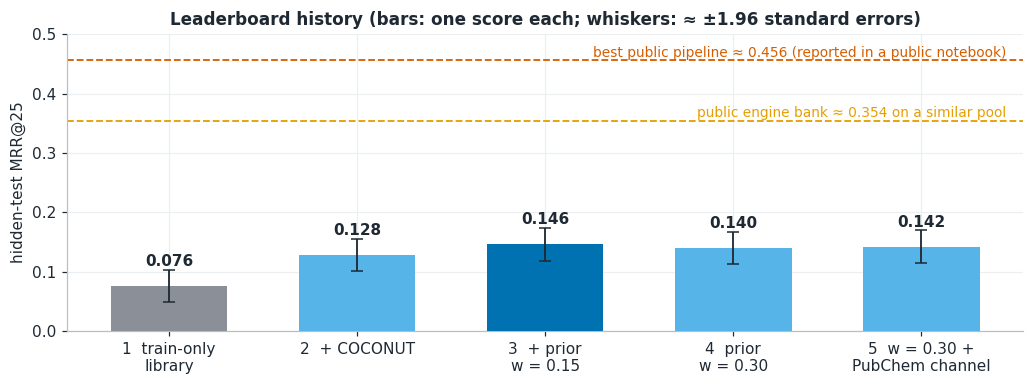

In [2]:
lb = pd.DataFrame({"label": ["1  train-only\nlibrary", "2  + COCONUT", "3  + prior\nw = 0.15", "4  prior\nw = 0.30", "5  w = 0.30 +\nPubChem channel"],
                   "score": [0.076, 0.128, 0.146, 0.140, 0.142]})
se = 0.28 / np.sqrt(400)                                   # approximate standard error of one leaderboard score (see text)
fig, ax = plt.subplots(figsize=(9.5, 3.6))
cols = [C["grey"], C["sky"], C["blue"], C["sky"], C["sky"]]
ax.bar(lb.label, lb.score, color=cols, width=0.62, zorder=3)
ax.errorbar(lb.label, lb.score, yerr=1.96 * se, fmt="none", ecolor=C["ink"], capsize=4, lw=1.2, zorder=4)
for i, v in enumerate(lb.score): ax.text(i, v + 1.96 * se + 0.006, f"{v:.3f}", ha="center", fontweight="bold")
ax.axhline(0.456, color=C["red"], ls="--", lw=1.2); ax.text(4.45, 0.462, "best public pipeline ≈ 0.456 (reported in a public notebook)", ha="right", color=C["red"], fontsize=9)
ax.axhline(0.354, color=C["orange"], ls="--", lw=1.2); ax.text(4.45, 0.36, "public engine bank ≈ 0.354 on a similar pool", ha="right", color=C["orange"], fontsize=9)
ax.set_ylim(0, 0.5); ax.set_ylabel("hidden-test MRR@25"); ax.set_title("Leaderboard history (bars: one score each; whiskers: ≈ ±1.96 standard errors)")
plt.tight_layout(); plt.show()

## 1. The task in plain language

A **mass spectrometer** breaks ionised molecules apart and records the mass-to-charge ratio (m/z) and intensity of what comes out. In an **MS/MS spectrum**, a selected ion
(the *precursor*) is fragmented and the resulting *fragments* are listed as peaks. We are given such spectra for natural-product molecules measured in biological extracts, and
must return **up to 25 candidate structures (SMILES)**, best first, for each molecule. One molecule usually has several spectra (different collision energies and ion forms).

Vocabulary used below:

* **Adduct**: how the molecule was charged, e.g. `[M+H]+` (gained a proton) or `[M-H]-`. The precursor m/z minus the adduct's mass shift gives the molecule's own **neutral mass**,
  which can be compared with the exact mass of any candidate structure. This *mass window* is a free and powerful filter.
* **Neutral loss**: precursor m/z minus a fragment's m/z, i.e. the piece that fell off (water, CO₂, ...). It is shared across molecules that lose the same group.
* **Mass defect**: the digits after the decimal point of a fragment's m/z. They encode its elemental composition (hydrogen-rich pieces have a larger defect), so they carry
  information that integer-binned spectra throw away.
* **Fingerprint**: a 1,024-bit vector flagging which substructures a molecule contains (Morgan fingerprint, radius 2). We predict it from the spectrum and rank candidates by similarity to
  the prediction.
* **Correct answer** (the metric): the first 14 characters of the InChIKey (the connectivity block) match after RDKit tautomer standardisation. Stereochemistry is ignored.

The hard part is that most test molecules are **not in the training data**, so the method has to generalise to unseen structures, and the answer has to be *in the candidate list* at all.

## 2. Data exploration

The training file has 2.54 million labelled spectra of 275,810 distinct molecules (253,832 after cleaning) from eleven collections. Only aggregate statistics are shown here (counts and histograms).

,spectra,molecules,spectra_per_molecule
source,,,
enveda-180,"1,153,785","182,941",6.3
pluskal_ms2,"527,581","46,821",11.3
riken,"347,171","15,892",21.8
gnps,"220,849","45,750",4.8
massbank,"101,727","9,180",11.1
mona,"92,416","11,681",7.9
spectraverse,"50,933","9,631",5.3
msdial,"40,765","9,127",4.5
drug_plus,"2,545","2,539",1.0


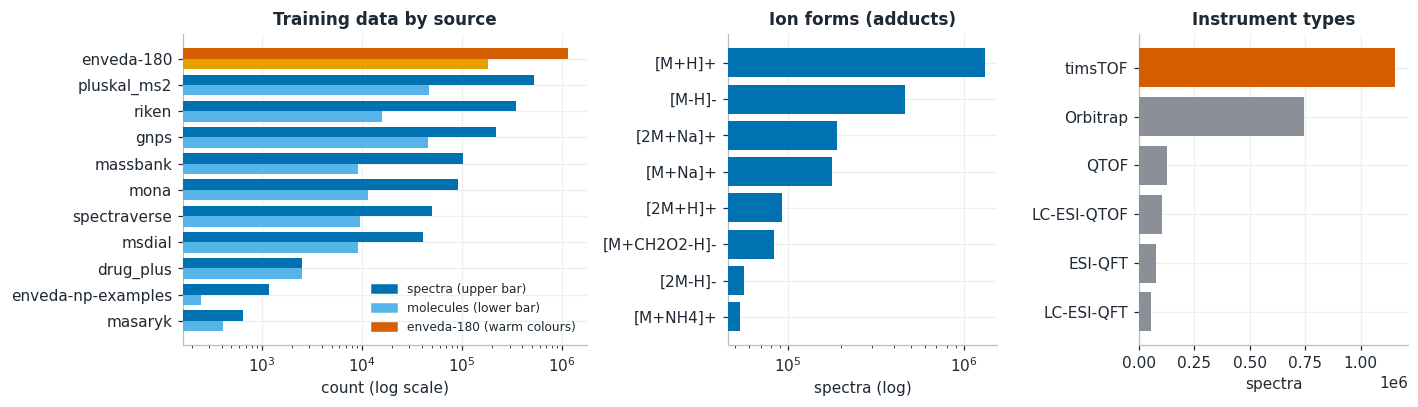

polarity: {'positive': 1899640, 'negative': 639968}


In [3]:
bs = pd.DataFrame(EDA["by_source"]).rename(columns={"ingest_lib": "source"})
bs["spectra_per_molecule"] = (bs.spectra / bs.molecules).round(1)
display(bs.assign(spectra=bs.spectra.map("{:,}".format), molecules=bs.molecules.map("{:,}".format)).set_index("source"))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.5, 1, 1]})
ax = axes[0]; y = np.arange(len(bs))[::-1]
ax.barh(y + 0.2, bs.spectra, 0.4, color=[C["red"] if s == "enveda-180" else C["blue"] for s in bs.source], zorder=3)
ax.barh(y - 0.2, bs.molecules, 0.4, color=[C["orange"] if s == "enveda-180" else C["sky"] for s in bs.source], zorder=3)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C["blue"], label="spectra (upper bar)"), Patch(color=C["sky"], label="molecules (lower bar)"), Patch(color=C["red"], label="enveda-180 (warm colours)")], loc="lower right", fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(bs.source); ax.set_xscale("log"); ax.set_xlabel("count (log scale)"); ax.set_title("Training data by source")
ax = axes[1]
ad = pd.Series(EDA["by_adduct"]); ax.barh(ad.index[::-1], ad.values[::-1], color=C["blue"], zorder=3); ax.set_xscale("log"); ax.set_title("Ion forms (adducts)"); ax.set_xlabel("spectra (log)")
ax = axes[2]
inst = pd.Series(EDA["by_instrument"]); ax.barh(inst.index[::-1], inst.values[::-1], color=[C["red"] if i == "timsTOF" else C["grey"] for i in inst.index[::-1]], zorder=3)
ax.set_title("Instrument types"); ax.set_xlabel("spectra")
plt.tight_layout(); plt.show()
print(f"polarity: {EDA['polarity']}")

**What to notice.** `enveda-180` (a red bar) is 45% of all spectra and 66% of the molecules, and it is the only collection measured on the same type of instrument as the hidden test
(timsTOF). But it is a *combinatorial library of nitrogen-rich compounds*, not natural products, so it matches the **instrument** but not the **chemistry**. The other collections are
public spectral libraries (GNPS, MassBank, MoNA, ...) with real natural products, measured on other instruments. This split between "right instrument, wrong chemistry" and
"right chemistry, wrong instrument" shapes the evaluation (section 4).

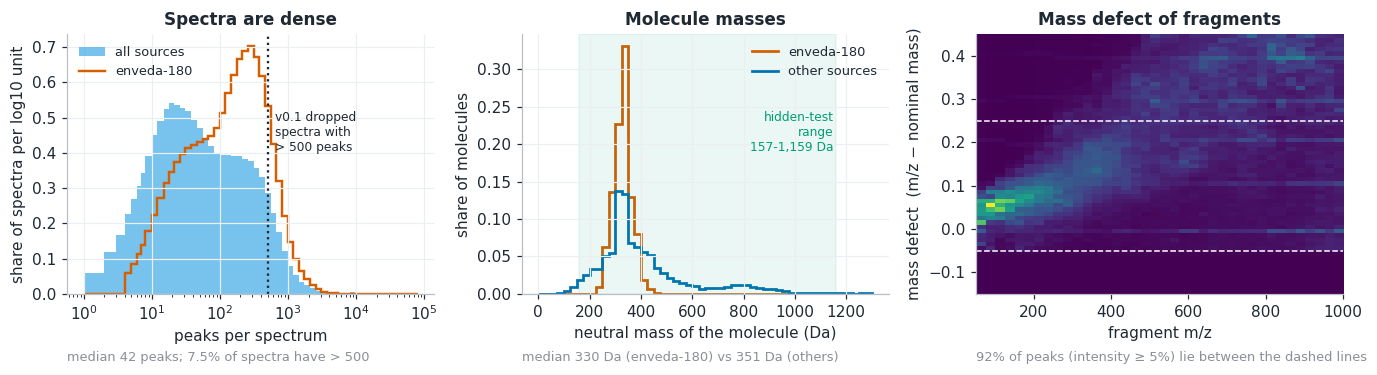

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
ax = axes[0]; e = np.array(EDA["peaks_edges"]); mid = np.sqrt(e[:-1] * e[1:])
dl = np.diff(np.log10(e))
ax.stairs(np.array(EDA["peaks_hist_all"]) / sum(EDA["peaks_hist_all"]) / dl, e, fill=True, color=C["sky"], alpha=0.8, label="all sources")
ax.stairs(np.array(EDA["peaks_hist_enveda-180"]) / sum(EDA["peaks_hist_enveda-180"]) / dl, e, color=C["red"], lw=1.6, label="enveda-180")
ax.axvline(500, color=C["ink"], ls=":"); ax.text(650, ax.get_ylim()[1] * 0.55, "v0.1 dropped\nspectra with\n> 500 peaks", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("peaks per spectrum"); ax.set_ylabel("share of spectra per log10 unit"); ax.set_title("Spectra are dense"); ax.legend(loc="upper left", fontsize=8.5)
note(ax, f"median {EDA['peaks_median']:.0f} peaks; {EDA['peaks_share_over_500']:.1%} of spectra have > 500", y=-0.22)

ax = axes[1]; me = np.array(EDA["mass_edges"])
for name, col in (("enveda-180", C["red"]), ("other sources", C["blue"])):
    h = np.array(EDA[f"mass_hist_{name}"]); ax.stairs(h / h.sum(), me, color=col, lw=1.8, label=name)
ax.axvspan(157, 1159, color=C["green"], alpha=0.08); ax.text(1150, ax.get_ylim()[1] * 0.55, "hidden-test\nrange\n157-1,159 Da", fontsize=8, color=C["green"], ha="right")
ax.set_xlabel("neutral mass of the molecule (Da)"); ax.set_ylabel("share of molecules"); ax.set_title("Molecule masses"); ax.legend(loc="upper right", fontsize=8.5)
note(ax, f"median {EDA['mass_median_enveda180']:.0f} Da (enveda-180) vs {EDA['mass_median_other']:.0f} Da (others)", y=-0.22)

ax = axes[2]
H = np.array(EDA["defect_hist"]); mz_e = np.array(EDA["defect_mz_edges"]); d_e = np.array(EDA["defect_edges"])
Hn = H / (H.sum(1, keepdims=True) + 1e-12)
im = ax.imshow(Hn.T, origin="lower", aspect="auto", extent=[mz_e[0], mz_e[-1], d_e[0], d_e[-1]], cmap="viridis")
for yv in (-0.05, 0.25): ax.axhline(yv, color="white", ls="--", lw=1)
ax.set_xlabel("fragment m/z"); ax.set_ylabel("mass defect  (m/z − nominal mass)"); ax.set_title("Mass defect of fragments"); ax.grid(False)
note(ax, f"{EDA['defect_share_in_band']:.0%} of peaks (intensity ≥ 5%) lie between the dashed lines", y=-0.22)
plt.tight_layout(); plt.show()

**Three design decisions follow directly from these panels.**

1. **Dense spectra** (left): 7.5% of spectra have more than 500 peaks, so dropping them (as the first baseline did) loses data that matters; v0.2 keeps every peak.
2. **Mass range** (middle): the hidden test spans 157-1,159 Da, wider than most training molecules. The feature grid stops at m/z 1,000 (a known limitation, section 7).
3. **Mass defect** (right): fragments do not scatter over the decimal part of m/z; they follow a narrow, mass-dependent ridge that rises with m/z. About 92% of the
   intensity sits between −0.05 and +0.25 Da. Section 5.2 spends feature columns exactly there, which turned out to be the single biggest modelling gain.

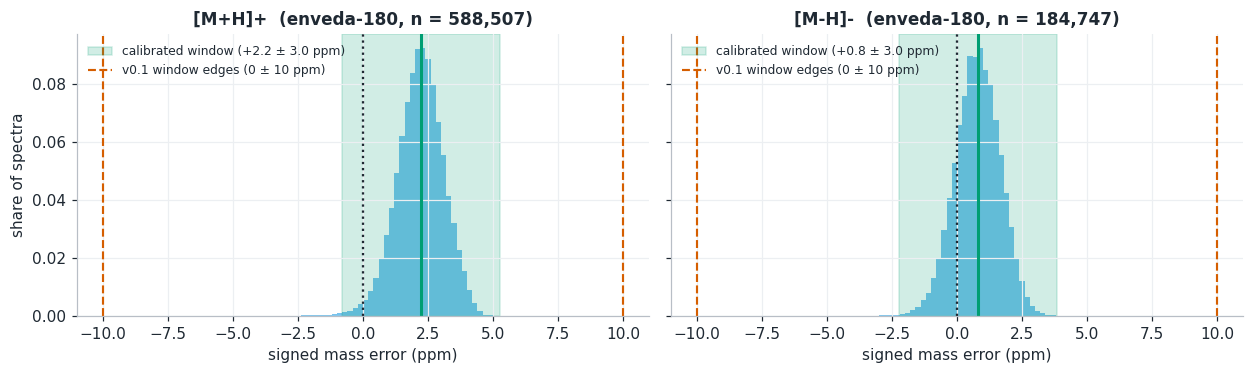

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5), sharey=True)
pol = T["mass_policy"].set_index("adduct"); edges = np.array(EDA["ppm_edges"]); mids = 0.5 * (edges[:-1] + edges[1:])
for ax, ad in zip(axes, ("[M+H]+", "[M-H]-")):
    h = np.array(EDA[f"ppm_hist_{ad}"]); ax.stairs(h / h.sum(), edges, fill=True, color=C["sky"], alpha=0.8)
    off, hw = pol.loc[ad, "bias_ppm"], pol.loc[ad, "halfwidth_ppm"]
    ax.axvspan(off - hw, off + hw, color=C["green"], alpha=0.18, label=f"calibrated window ({off:+.1f} ± {hw:.1f} ppm)")
    ax.axvline(0, color=C["ink"], ls=":"); ax.axvline(off, color=C["green"], lw=2)
    for xv in (-10, 10): ax.axvline(xv, color=C["red"], ls="--", lw=1.4, label="v0.1 window edges (0 ± 10 ppm)" if xv < 0 else None)
    ax.set_xlim(-11, 11); ax.set_xlabel("signed mass error (ppm)"); ax.set_title(f"{ad}  (enveda-180, n = {EDA['ppm_n_' + ad]:,})"); ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("share of spectra")
plt.tight_layout(); plt.show()

The instrument is **not centred on zero**: the median signed mass error is +2.2 ppm for `[M+H]+` and +0.8 ppm for `[M-H]-`. The file's own `precursor_error_ppm` column is
*unsigned* (and computed with a slightly different hydrogen mass), so it hides this offset. Section 5.1 shows what centring the mass window on the measured offset buys.

## 3. Method

```
spectra of one molecule ─► features ─► deep MLP ─► 1,024-bit fingerprint (per spectrum)
        (fragments + neutral losses      │
         in mass-defect sub-bins)        ▼
                                   mean over the molecule's spectra
                                         │
candidate library ──► mass window ───────┼──► score = z(cosine(prediction, candidate)) + w · popularity
 (train molecules + COCONUT)             │
                                         ▼
                                   top 25 SMILES
```

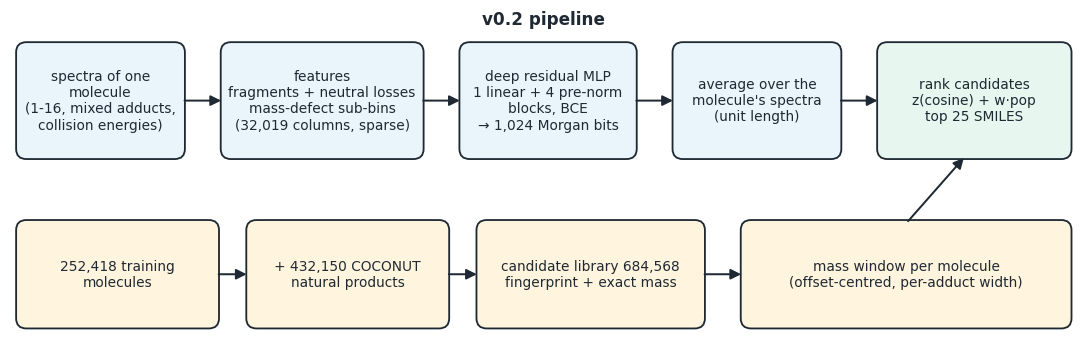

In [6]:
fig, ax = plt.subplots(figsize=(12.5, 3.9)); ax.set_xlim(0, 12.5); ax.set_ylim(0, 3.9); ax.axis("off")
def box(x, y, w, h, text, fc, ec=C["ink"], fs=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12", fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=C["ink"])
def arr(x0, y0, x1, y1): ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=14, color=C["ink"], lw=1.3))
box(0.1, 2.2, 1.9, 1.3, "spectra of one\nmolecule\n(1-16, mixed adducts,\ncollision energies)", "#EAF4FB")
box(2.5, 2.2, 2.3, 1.3, "features\nfragments + neutral losses\nmass-defect sub-bins\n(32,019 columns, sparse)", "#EAF4FB")
box(5.3, 2.2, 2.0, 1.3, "deep residual MLP\n1 linear + 4 pre-norm\nblocks, BCE\n→ 1,024 Morgan bits", "#EAF4FB")
box(7.8, 2.2, 1.9, 1.3, "average over the\nmolecule's spectra\n(unit length)", "#EAF4FB")
box(10.2, 2.2, 2.2, 1.3, "rank candidates\nz(cosine) + w·pop\ntop 25 SMILES", "#E7F6EE")
for x0, x1 in ((2.0, 2.5), (4.8, 5.3), (7.3, 7.8), (9.7, 10.2)): arr(x0, 2.85, x1, 2.85)
box(0.1, 0.2, 2.3, 1.2, "252,418 training\nmolecules", "#FFF4DD"); box(2.8, 0.2, 2.3, 1.2, "+ 432,150 COCONUT\nnatural products", "#FFF4DD")
box(5.5, 0.2, 2.6, 1.2, "candidate library 684,568\nfingerprint + exact mass", "#FFF4DD"); box(8.6, 0.2, 3.8, 1.2, "mass window per molecule\n(offset-centred, per-adduct width)", "#FFF4DD")
arr(2.4, 0.8, 2.8, 0.8); arr(5.1, 0.8, 5.5, 0.8); arr(8.1, 0.8, 8.6, 0.8); arr(10.5, 1.4, 11.2, 2.2)
ax.text(6.25, 3.75, "v0.2 pipeline", ha="center", fontsize=11, fontweight="bold")
plt.show()

**Features (v0.2c).** Each spectrum becomes two sparse blocks: one over **fragment m/z**, one over **neutral loss** (precursor m/z − fragment m/z). Each block uses, per nominal
mass, 15 sub-bins of 0.02 Da across the mass-defect band [−0.05, +0.25) plus one overflow column; values are square-root intensities, unit length per block. Acquisition metadata
(neutral mass, collision energy, polarity, instrument, adduct) is appended.

**Model.** A deep residual MLP (linear layer of 1,024 units, four pre-norm residual blocks with dropout 0.3, 1,024 sigmoid outputs, binary cross-entropy, AdamW, early stopping on a
scaffold-grouped inner holdout), trained on 633,198 spectra of 235,854 molecules (all cleaned molecules outside validation, at most three spectra each).

**Ranking.** For each test *molecule*: average the predicted fingerprints of its spectra, intersect the spectra's mass windows, keep library molecules whose exact mass is inside,
and rank them by cosine similarity (later standardised within the window and combined with a popularity prior, section 6).

## 4. How we measure progress

The hidden test cannot be scored locally, so every modelling choice was judged on a **validation set that mimics it as far as possible**:

* **Scaffold-grouped split** (80/20 on the Murcko scaffold with stereochemistry removed; each acyclic molecule its own group; a hard check that no validation molecule appears in training).
  Without it, stereoisomers leak across the split and scores measure memorisation (an early version scored 0.01 for this reason).
* **A candidate pool of 229,964 molecules** that always contains the true answer ("oracle" pool), because a train-only pool cannot contain an unseen molecule. The pool size matters a lot:

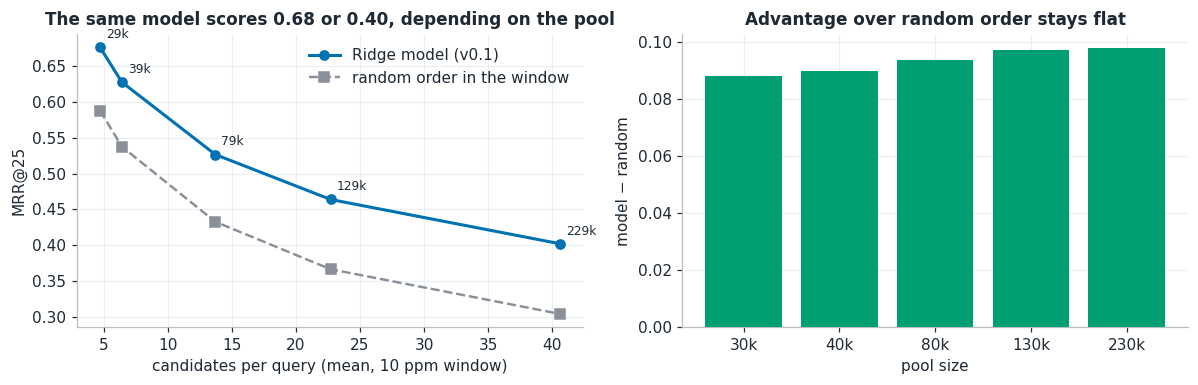

In [7]:
b = T["bench_v1"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.plot(b.cand_per_query, b.model, "o-", color=C["blue"], lw=2, label="Ridge model (v0.1)"); ax.plot(b.cand_per_query, b.random, "s--", color=C["grey"], lw=1.6, label="random order in the window")
for _, r in b.iterrows(): ax.annotate(f"{int(r.pool/1000)}k", (r.cand_per_query, r.model), textcoords="offset points", xytext=(4, 6), fontsize=8)
ax.set_xlabel("candidates per query (mean, 10 ppm window)"); ax.set_ylabel("MRR@25"); ax.set_title("The same model scores 0.68 or 0.40, depending on the pool"); ax.legend()
ax = axes[1]
ax.bar(b.pool.astype(str).map(lambda s: f"{int(s)/1000:.0f}k"), b.model - b.random, color=C["green"], zorder=3)
ax.set_title("Advantage over random order stays flat"); ax.set_xlabel("pool size"); ax.set_ylabel("model − random")
plt.tight_layout(); plt.show()

Left: with a 30k pool the first baseline scored 0.68, but most of that is the mass window alone (random order inside the window already scores 0.59). With 230k molecules the same model
scores 0.40. The right panel is the useful number: the model's *advantage over random* is roughly constant (0.09-0.10), so **model quality and pool size are separate problems**. From then on we
always report the score **and** the random-order score for the same candidates.

* **Two reporting slices.** *mixed* (2,000 seeded validation spectra from all sources, ±10 ppm): chemistry like the test, other instruments. *enveda-180* (all 2,818 validation spectra
  of that collection, calibrated window): the test's instrument, but combinatorial chemistry. The truth lies between the two.
* **Molecule-level scoring** (pooling the spectra of a molecule) is used for the submissions but not for most ablations, which are per spectrum.

> **Caveat that matters later:** validation molecules are scaffold-disjoint from training but usually have *close analogues* in it (at the largest training size, every enveda-180
> validation molecule has a training molecule with Tanimoto similarity ≥ 0.4). The local benchmark therefore overstates performance on genuinely novel structures. Section 5.5 quantifies this.

## 5. Which modelling choices mattered

### 5.1 Calibrate the mass window

Only candidates whose exact mass fits the precursor are considered, so the window decides how many isomers compete. A window centred on the measured instrument offset can be much tighter at
equal coverage.

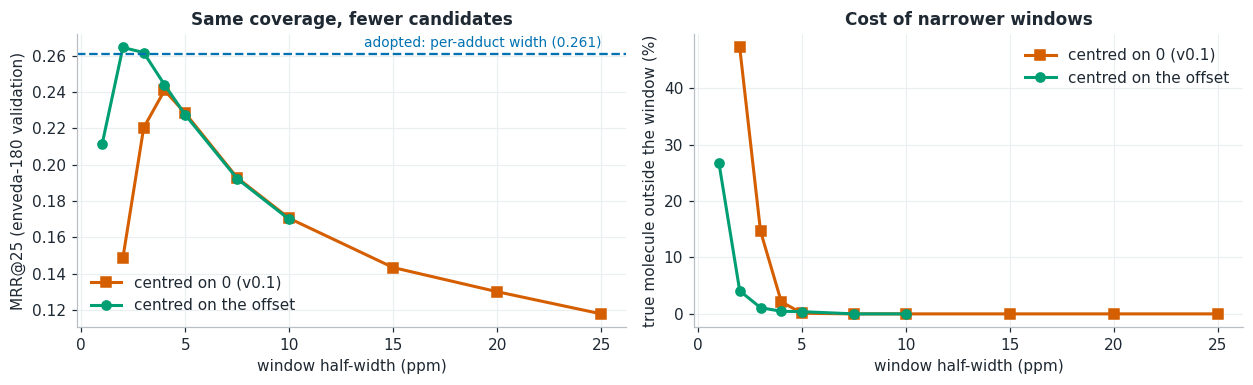

,spectra,offset (ppm),robust sd (ppm),window half-width (ppm)
adduct,,,,
[M+CH2O2-H]-,24556,1.94,1.01,3.52
[M+Cl]-,2407,-0.16,1.22,4.27
[M+H]+,588507,2.22,0.87,3.04
[M+K]+,1084,0.23,3.25,11.36
[M+NH4]+,4702,1.51,2.05,7.16
[M+Na]+,15957,1.03,1.36,4.76
[M-H]-,184747,0.80,0.87,3.03


In [8]:
p3 = T["p3"]; e = p3[p3.slice == "enveda180_val"]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
for pol_, lab, col, mk in (("v01_uncentered", "centred on 0 (v0.1)", C["red"], "s"), ("centered", "centred on the offset", C["green"], "o")):
    d = e[e.policy == pol_].sort_values("tol_ppm")
    axes[0].plot(d.tol_ppm, d.model, mk + "-", color=col, lw=2, label=lab); axes[1].plot(d.tol_ppm, d.miss_pct, mk + "-", color=col, lw=2, label=lab)
adopted = e[e.policy == "centered_adduct_sigma"].iloc[0]
axes[0].axhline(adopted.model, color=C["blue"], ls="--"); axes[0].text(e.tol_ppm.max(), adopted.model + 0.004, f"adopted: per-adduct width ({adopted.model:.3f})", ha="right", color=C["blue"], fontsize=9)
axes[0].set_xlabel("window half-width (ppm)"); axes[0].set_ylabel("MRR@25 (enveda-180 validation)"); axes[0].set_title("Same coverage, fewer candidates"); axes[0].legend()
axes[1].set_xlabel("window half-width (ppm)"); axes[1].set_ylabel("true molecule outside the window (%)"); axes[1].set_title("Cost of narrower windows"); axes[1].legend()
plt.tight_layout(); plt.show()
display(T["mass_policy"].rename(columns={"n": "spectra", "bias_ppm": "offset (ppm)", "sd_ppm": "robust sd (ppm)", "halfwidth_ppm": "window half-width (ppm)"}).round(2).set_index("adduct"))

Centring the window on the +2.2 ppm offset and using a per-adduct width (3.5 robust standard deviations, never below 3 ppm) raised the enveda-180 score from **0.170 to 0.261** at 0.7% window
misses, and halved the median number of candidates (68 → 33). **Caveat:** these offsets were fitted on enveda-180 *training* spectra; whether the hidden test shares the calibration is untested.

### 5.2 Better features: neutral losses, then finer, mass-defect-aware bins

One change per version, all with the same Ridge regression and the same calibrated window (so the ladder isolates the *features*):

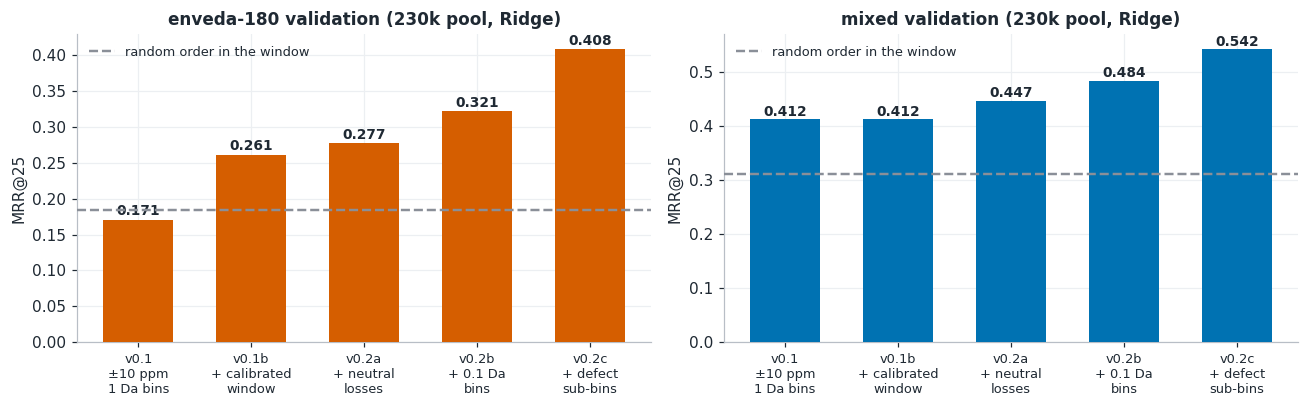

In [9]:
lad = pd.DataFrame({"step": ["v0.1\n±10 ppm\n1 Da bins", "v0.1b\n+ calibrated\nwindow", "v0.2a\n+ neutral\nlosses", "v0.2b\n+ 0.1 Da\nbins", "v0.2c\n+ defect\nsub-bins"],
                    "enveda-180": [0.1705, 0.2611, 0.2767, 0.3214, 0.4084], "mixed": [0.4125, 0.4125, 0.4469, 0.4839, 0.5425]})
rand = {"enveda-180": 0.1835, "mixed": 0.3111}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
for ax, k, col in zip(axes, ("enveda-180", "mixed"), (C["red"], C["blue"])):
    ax.bar(lad.step, lad[k], color=col, width=0.62, zorder=3); ax.axhline(rand[k], color=C["grey"], ls="--", lw=1.6, label="random order in the window", zorder=4)
    for i, v in enumerate(lad[k]): ax.text(i, v + 0.006, f"{v:.3f}", ha="center", fontsize=9, fontweight="bold")
    ax.set_title(f"{k} validation (230k pool, Ridge)"); ax.set_ylabel("MRR@25"); ax.tick_params(axis="x", labelsize=8.5); ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()

| Step | Idea | Gain (enveda-180 / mixed), paired bootstrap 95% CI where computed |
|---|---|---|
| neutral losses | shed pieces (H₂O, CO, CO₂, ...) are shared across molecules even when fragments differ | +0.016 / +0.034 |
| 0.1 Da bins | a 1 Da bin discards the mass defect, i.e. elemental composition | +0.045 / +0.037 |
| mass-defect sub-bins | spend columns only where the defect lives ([−0.05, 0.25)) at 0.02 Da | **+0.087 / +0.059** |

The ladder was monotone in resolution, and each gain survived a regularisation sweep (so it is not an artefact of the ridge penalty). The finest step needs 32k columns, the ceiling of
the closed-form solver, so finer resolution calls for a different learner, which is the next subsection.

### 5.3 A better learner needs far more data, and then it wins

An MLP trained on the same 62k spectra *lost* to Ridge by 0.11-0.13 in every configuration. The question was whether MLPs are the wrong tool, or the training set simply too small
(62k spectra is 3.6% of the cleaned data). A learning-curve test with nested training sets answered it:

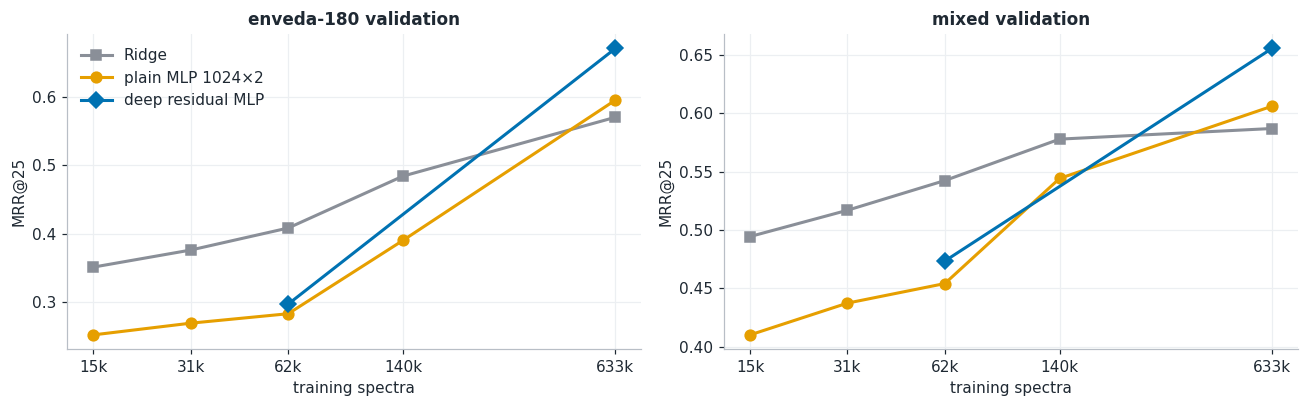

,training spectra,deep,mlp,ridge
tier,,,,
A25,"15,423",NaN,0.2523,0.3513
A50,"30,818",NaN,0.2694,0.3762
A,"61,701",0.2973,0.2832,0.4084
B,"139,679",NaN,0.3903,0.4842
D,"633,198",0.6706,0.5951,0.5701


In [10]:
s = T["scale"]; s = s[s.slice == "enveda180"].copy(); s["family"] = s.arch
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
for ax, sl, ttl in zip(axes, ("enveda180", "mixed_2000"), ("enveda-180 validation", "mixed validation")):
    d = T["scale"]; d = d[d.slice == sl]
    for arch, col, lab, mk in (("ridge", C["grey"], "Ridge", "s"), ("mlp", C["orange"], "plain MLP 1024×2", "o"), ("deep", C["blue"], "deep residual MLP", "D")):
        x = d[d.arch == arch].sort_values("n_spectra"); ax.plot(x.n_spectra, x.model, mk + "-", color=col, lw=2, ms=7, label=lab)
    ax.set_xscale("log"); ax.set_xticks([15423, 30818, 61701, 139679, 633198]); ax.set_xticklabels(["15k", "31k", "62k", "140k", "633k"]); ax.minorticks_off()
    ax.set_xlabel("training spectra"); ax.set_ylabel("MRR@25"); ax.set_title(ttl)
axes[0].legend(loc="upper left")
plt.tight_layout(); plt.show()
t = T["scale"][T["scale"].slice == "enveda180"].pivot_table(index="tier", columns="arch", values="model").reindex(["A25", "A50", "A", "B", "D"])
t.insert(0, "training spectra", ["15,423", "30,818", "61,701", "139,679", "633,198"]); t.columns.name = None; display(t.round(4))

The MLP learns much faster from data than Ridge (+0.31 vs +0.16 on enveda-180 from 62k to 633k spectra), overtakes it between 140k and 633k spectra, and **depth only pays at scale**
(deep minus plain MLP: +0.014 at 62k, +0.076 at 633k). The 62k verdict "MLP < Ridge" was a small-data artefact. Bit-level quality tells the same story (mean per-bit AUC 0.80 for the
deep model against 0.72 for Ridge on all validation molecules). Training took 50 minutes on a laptop GPU.

Two negative results from the same experiments, kept because they save time: a Bernoulli log-likelihood ranking rule was *worse* than plain cosine for both models, and clipping Ridge
outputs to [0, 1] before the cosine cost 0.007 (their negative outputs carry ranking information).

### 5.4 Pool a molecule's spectra into one query

A submission needs one ranking per molecule, but a molecule has 1-16 spectra at different collision energies and adducts. Averaging the predicted fingerprints and intersecting the mass
windows beats scoring spectra one at a time, and the gain grows with model quality:

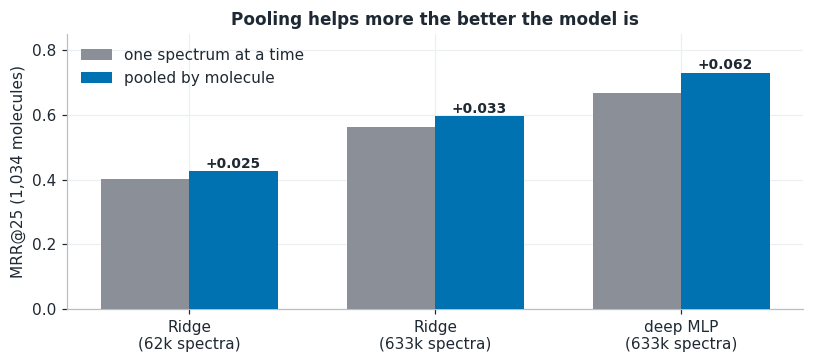

In [11]:
pl = T["pooling"].copy(); pl["model"] = pl.model.map({"ridge_A (v0.2c)": "Ridge\n(62k spectra)", "ridge_D": "Ridge\n(633k spectra)", "deep_D": "deep MLP\n(633k spectra)"})
fig, ax = plt.subplots(figsize=(7.5, 3.4)); x = np.arange(len(pl)); w = 0.36
ax.bar(x - w/2, pl.per_spectrum_mrr, w, color=C["grey"], label="one spectrum at a time", zorder=3); ax.bar(x + w/2, pl.pooled_mrr, w, color=C["blue"], label="pooled by molecule", zorder=3)
for i, r in pl.iterrows(): ax.text(i + w/2, r.pooled_mrr + 0.01, f"+{r.pooled_minus_single:.3f}", ha="center", fontweight="bold", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(pl.model); ax.set_ylabel("MRR@25 (1,034 molecules)"); ax.set_ylim(0, 0.85); ax.legend(loc="upper left")
ax.set_title("Pooling helps more the better the model is"); plt.tight_layout(); plt.show()

### 5.5 How well does this transfer to molecules unlike the training set?

This is the most important caveat on all local numbers. We binned validation molecules by their **maximum Tanimoto similarity to any training molecule** (1.0 = identical fingerprint
overlap, below 0.3 = structurally unrelated) and compared the deep model with Ridge at the full training size:

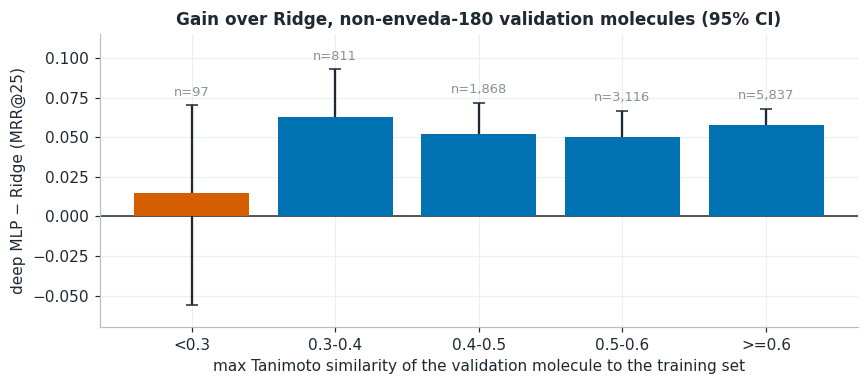

In [12]:
nv = T["novelty"]; nv = nv[nv.group == "all non-enveda-180"].copy(); order = ["<0.3", "0.3-0.4", "0.4-0.5", "0.5-0.6", ">=0.6"]
nv = nv.set_index("max_tanimoto").loc[order].reset_index()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(nv.max_tanimoto, nv["diff"], color=[C["red"] if t == "<0.3" else C["blue"] for t in nv.max_tanimoto], zorder=3)
ax.errorbar(nv.max_tanimoto, nv["diff"], yerr=[nv["diff"] - nv.ci_lo, nv.ci_hi - nv["diff"]], fmt="none", ecolor=C["ink"], capsize=4)
for i, r in nv.iterrows(): ax.text(i, r.ci_hi + 0.006, f"n={int(r.n):,}", ha="center", fontsize=8.5, color=C["grey"])
ax.axhline(0, color=C["ink"], lw=1); ax.set_ylim(-0.07, 0.115); ax.set_xlabel("max Tanimoto similarity of the validation molecule to the training set"); ax.set_ylabel("deep MLP − Ridge (MRR@25)")
ax.set_title("Gain over Ridge, non-enveda-180 validation molecules (95% CI)"); plt.tight_layout(); plt.show()

The deep model's advantage is **+0.05 to +0.06 wherever a similar molecule exists in training, but +0.015 (confidence interval −0.06 to +0.07) for truly dissimilar molecules (< 0.3)**, and
only 97 validation molecules fall in that last bin. For the real test (natural products without close training analogues) the honest expectation is the left bar, not the right ones.
This foreshadows the leaderboard behaviour in section 6.

## 6. The candidate pool and the leaderboard

A ranker can only rank what is in the list. The validation numbers above assume the true molecule is a candidate; on the hidden test it usually is not, because the library built from
training molecules holds only molecules that were measured before.

### 6.1 First submission: train-only library, 0.076

The deep model with a library of the 252,418 training molecules scored **0.076**. With a molecule-level MRR of roughly 0.55-0.65 *when the answer is in the library*, this means about
12-14% of the hidden molecules are in the training set (an estimate that rests on that assumption). The other ~86% score zero whatever the model is.

### 6.2 COCONUT: +432,150 natural products → 0.128

COCONUT is a public database of natural products, so it is the obvious source of candidates for a natural-product test. Its structures have **no spectra**, so the benefit cannot be
validated locally; but the *cost* of a bigger pool can. Adding COCONUT as decoys to the validation pool:

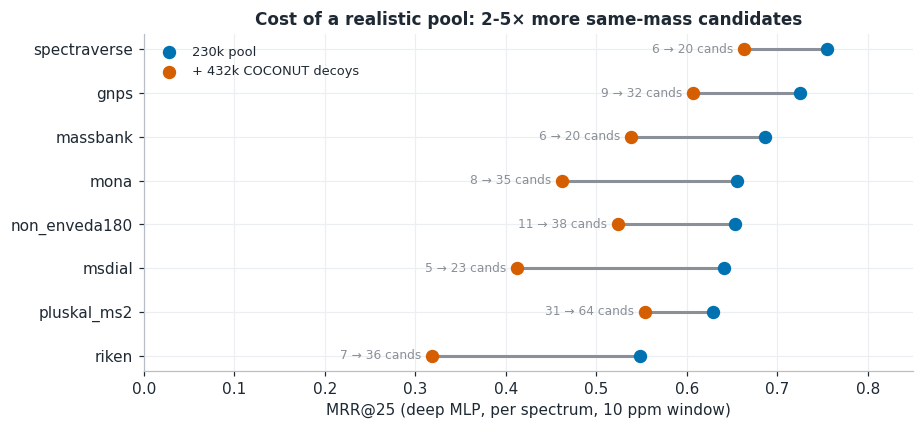

In [13]:
ps = T["p7a_src"]; ps = ps[ps.slice.str.startswith("src_") | (ps.slice == "non_enveda180")].copy()
A_ = ps[ps.pool.str.startswith("A")].set_index("slice"); B_ = ps[ps.pool.str.startswith("B")].set_index("slice")
idx = [s for s in A_.index if s in B_.index]; d = pd.DataFrame({"A": A_.loc[idx, "model"], "B": B_.loc[idx, "model"], "cA": A_.loc[idx, "cands_median"], "cB": B_.loc[idx, "cands_median"]})
d = d.sort_values("A"); d.index = [i.replace("src_", "") for i in d.index]
fig, ax = plt.subplots(figsize=(8.5, 4)); y = np.arange(len(d))
ax.hlines(y, d.B, d.A, color=C["grey"], lw=2, zorder=2); ax.scatter(d.A, y, color=C["blue"], s=60, zorder=3, label="230k pool"); ax.scatter(d.B, y, color=C["red"], s=60, zorder=3, label="+ 432k COCONUT decoys")
for yi, (_, r) in zip(y, d.iterrows()): ax.text(min(r.A, r.B) - 0.012, yi, f"{r.cA:.0f} → {r.cB:.0f} cands", ha="right", va="center", fontsize=8, color=C["grey"])
ax.set_yticks(y); ax.set_yticklabels(d.index); ax.set_xlabel("MRR@25 (deep MLP, per spectrum, 10 ppm window)"); ax.set_xlim(0.0, 0.85); ax.legend(loc="upper left", fontsize=8.5)
ax.set_title("Cost of a realistic pool: 2-5× more same-mass candidates"); plt.tight_layout(); plt.show()

The bigger pool costs about **0.13 MRR on already-reachable natural-product-like molecules** (median candidates 11 → 38), because there are 2-5× more isomers with the same mass; the
model-minus-random gap stays flat, so this is more competition, not a worse model. Yet on the leaderboard COCONUT raised the score from 0.076 to **0.128**: the molecules it makes
reachable more than pay for the cost. A rough decomposition (an estimate, not a measurement): about 0.063 of the 0.128 comes from molecules also in the training set (diluted by the bigger pool)
and about 0.065 from COCONUT-only molecules, roughly **12-19% of the hidden molecules**. Together with the training overlap, perhaps 25-33% of hidden molecules are reachable at all.

### 6.3 A documentation prior breaks ties: 0.146

Among candidates with the same mass and similar predicted fingerprints, the better-documented structure is more often the answer. The public *PubChem popularity prior* gives each structure
`pop = ln(1 + substance records) + ln(1 + PubMed articles)`. We score `z(cosine within the mass window) + w · pop` and the leaderboard moved **0.128 → 0.146** at w = 0.15. Doubling the
weight to 0.30 scored 0.140: the gain saturates (consistent with the dataset's own warning that a large weight pushes down correct but rarely studied structures).

### 6.4 PubChem mass-window channel: built, benchmarked, and neutral

Since ~70% of the hidden molecules are in neither the training set nor COCONUT, we added a channel that pulls every PubChem structure inside each query's mass window (PubChem: 105.9 million
structures sorted by neutral mass, so a window is a binary search), fingerprints those structures on the fly, and ranks them together with the library using the same prior. The windows are small enough:

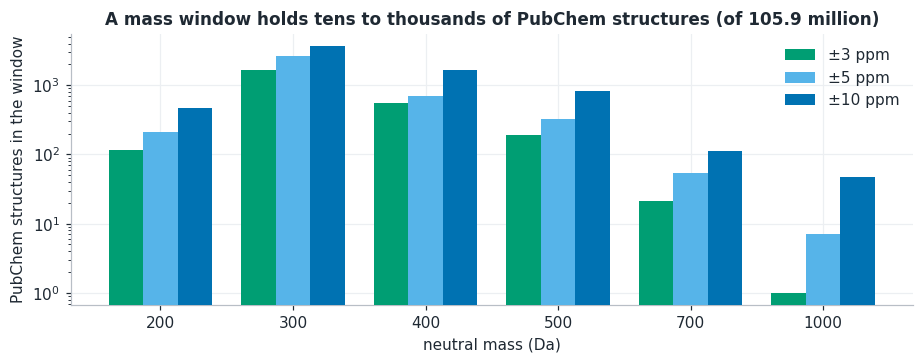

In [14]:
win = pd.DataFrame({"neutral mass (Da)": [200, 300, 400, 500, 700, 1000], "±3 ppm": [114, 1662, 556, 191, 21, 1], "±5 ppm": [208, 2629, 703, 330, 54, 7], "±10 ppm": [471, 3627, 1660, 826, 112, 48]})
fig, ax = plt.subplots(figsize=(8.5, 3.4)); x = np.arange(len(win)); w = 0.26
for j, (c, col) in enumerate((("±3 ppm", C["green"]), ("±5 ppm", C["sky"]), ("±10 ppm", C["blue"]))): ax.bar(x + (j - 1) * w, win[c], w, color=col, label=c, zorder=3)
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(win["neutral mass (Da)"]); ax.set_xlabel("neutral mass (Da)"); ax.set_ylabel("PubChem structures in the window"); ax.legend()
ax.set_title("A mass window holds tens to thousands of PubChem structures (of 105.9 million)"); plt.tight_layout(); plt.show()

Naively merging them hurts: thousands of PubChem isomers out-score the library candidates on cosine. So library candidates receive a **source prior (bonus)**, since a structure we have seen is
a priori much more likely to be the answer than one of thousands of same-mass PubChem isomers. We benchmarked three scenarios on labelled validation molecules, with the deep model's predictions:
**A** truth in the library, tier off (reference); **B** truth *removed* from the library, PubChem on (molecules reachable only through PubChem); **C** truth in the library, PubChem on (the cost).

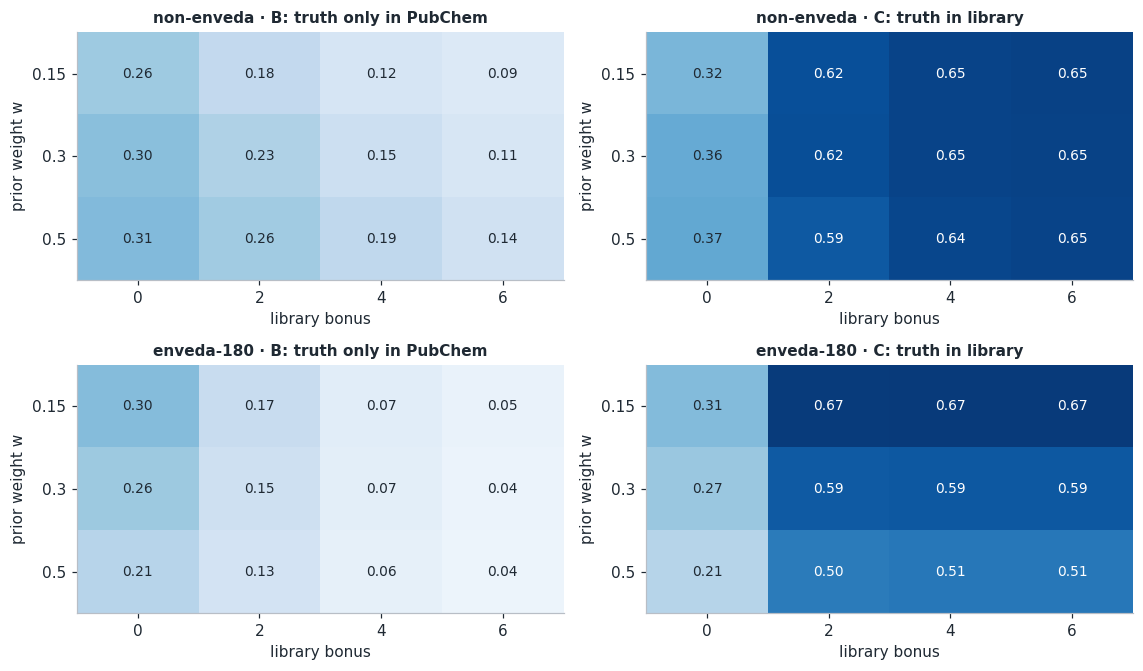

Reference A (truth in library, PubChem off), MRR@25 by prior weight w:


w,0.15,0.30,0.50
slice,,,
E180,0.669,0.590,0.518
nonE,0.664,0.656,0.634


In [15]:
p = T["p7d"]; p = p[p.scenario != "A"]
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.2))
for r, sl in enumerate(("nonE", "E180")):
    for c_, sc in enumerate(("B", "C")):
        ax = axes[r, c_]; d = p[(p.slice == sl) & (p.scenario == sc)].pivot(index="w", columns="bonus", values="mrr")
        im = ax.imshow(d.values, cmap="Blues", vmin=0, vmax=0.7, aspect="auto"); ax.grid(False)
        ax.set_xticks(range(d.shape[1])); ax.set_xticklabels([f"{b:g}" for b in d.columns]); ax.set_yticks(range(d.shape[0])); ax.set_yticklabels([f"{w_:g}" for w_ in d.index])
        for i in range(d.shape[0]):
            for j in range(d.shape[1]): ax.text(j, i, f"{d.values[i, j]:.2f}", ha="center", va="center", color="white" if d.values[i, j] > 0.4 else C["ink"], fontsize=9)
        ax.set_title(("non-enveda" if sl == "nonE" else "enveda-180") + " · " + ("B: truth only in PubChem" if sc == "B" else "C: truth in library"), fontsize=10)
        ax.set_xlabel("library bonus"); ax.set_ylabel("prior weight w")
A_ref = T["p7d"][T["p7d"].scenario == "A"].groupby(["slice", "w"]).mrr.first().unstack()
plt.tight_layout(); plt.show()
print("Reference A (truth in library, PubChem off), MRR@25 by prior weight w:"); display(A_ref.round(3))

With a bonus of 2 the cost on reachable molecules mostly disappears (scenario C within about 0.05 of A on both slices) while molecules reachable only through PubChem keep **0.13-0.26** (B).
Combining this with the assumption that ~28% of hidden molecules are reachable through the library and a share *p* of the remaining 72% are in PubChem, the benchmark predicted:

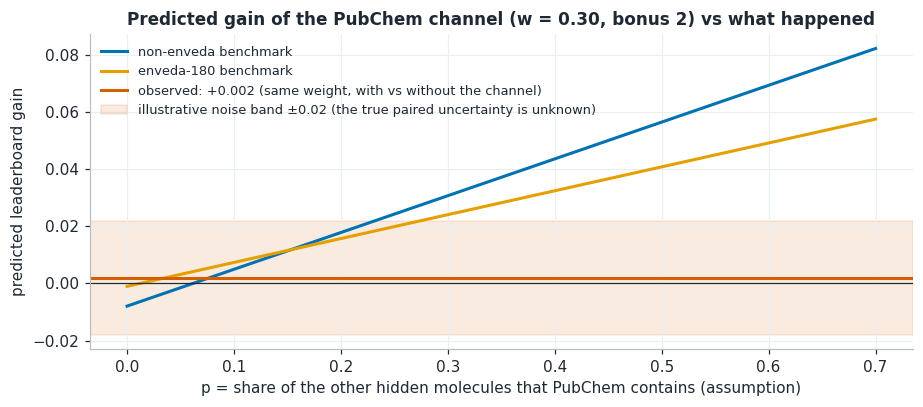

In [16]:
p7 = T["p7d"]; L, scale = 0.28, 0.79                      # L: reachable share (estimate); scale: benchmark -> leaderboard calibration for reachable molecules
Aw = p7[p7.scenario == "A"].set_index(["slice", "w"]).mrr
def gain(sl, w, bonus, pp):
    B_ = p7[(p7.slice == sl) & (p7.w == w) & (p7.bonus == bonus) & (p7.scenario == "B")].mrr.iloc[0]; C_ = p7[(p7.slice == sl) & (p7.w == w) & (p7.bonus == bonus) & (p7.scenario == "C")].mrr.iloc[0]
    return scale * (L * (C_ - Aw[(sl, w)]) + 0.72 * pp * B_)
ps_ = np.linspace(0, 0.7, 50)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for sl, col, lab in (("nonE", C["blue"], "non-enveda benchmark"), ("E180", C["orange"], "enveda-180 benchmark")): ax.plot(ps_, [gain(sl, 0.3, 2.0, q) for q in ps_], lw=2, color=col, label=lab)
ax.axhline(0.002, color=C["red"], lw=2, label="observed: +0.002 (same weight, with vs without the channel)")
ax.axhspan(0.002 - 0.02, 0.002 + 0.02, color=C["red"], alpha=0.12, label="illustrative noise band ±0.02 (the true paired uncertainty is unknown)")
ax.axhline(0, color=C["ink"], lw=0.8); ax.set_xlabel("p = share of the other hidden molecules that PubChem contains (assumption)"); ax.set_ylabel("predicted leaderboard gain")
ax.set_title("Predicted gain of the PubChem channel (w = 0.30, bonus 2) vs what happened"); ax.legend(loc="upper left", fontsize=8.5); plt.tight_layout(); plt.show()

**Outcome: the leaderboard moved from 0.140 (same weight, PubChem off) to 0.142 (on), i.e. +0.002.** The predicted gain was +0.01 to +0.05. How strong is the evidence against it? An unpaired
comparison of two scores has a standard error of about 0.02, so by itself this does not rule out the lower end of the prediction; but the two rankings share the same model and library and differ only
in the PubChem candidates, so the paired uncertainty is smaller (we could not measure it), and the observed gain sits at the bottom of what the benchmark expected (a PubChem share *p* near zero in
the model). We read it as *at most a small effect*, not as proof of none. Three explanations are consistent with the evidence and were **not** separated: (1) the benchmark is optimistic, because its truths are well-documented known compounds whose
close analogues are in training, so fingerprint cosine separates them better than it will for novel natural products; (2) fewer hidden molecules are in PubChem than assumed (some are "potential,
never isolated" molecules); (3) with thousands of same-mass isomers, our cosine cannot place the answer in the top 25 even with the prior. The channel is implemented and left switched off.

### 6.5 How much can one leaderboard score tell us?

The three scores 0.140, 0.142 and 0.146 are not distinguishable (section 0). Practical consequences, which shaped the second half of the project: spend a submission only on changes expected to
move the score by ≳ 0.03; do not tune weights on single submissions; and use the leaderboard as the arbiter only for questions the local benchmark cannot answer (pool membership, novel-molecule behaviour).

## 7. Where is the gap, and limitations

**The gap is the ranker, not the pool.** Public notebooks report leaderboard scores of about 0.354 for an engine bank on essentially the same train + COCONUT pool (710,701 structures), 0.358 after adding a
forward-model re-scoring (ICEBERG), 0.380 with ICEBERG and GLACIER at full weight, and 0.450-0.456 for the full stack (analog propagation from similar training spectra, public pretrained fingerprint
networks, forward models that *simulate* a candidate's spectrum, a trained re-ranker, a gated PubChem channel and the same popularity prior). Our 0.146 on a comparable pool says that **a spectrum → fingerprint MLP,
validated on molecules with training analogues, is the weak part for novel natural products**; forward models and analog propagation do not need the candidate to resemble anything the network was trained on.

**Limitations of this work (v0.2)**

| # | Limitation | Consequence |
|---|---|---|
| 1 | Hidden test is scored only through leaderboard submissions; one score has a standard error of ≈ 0.014 | differences below ≈ 0.01 (e.g. the prior weight, the PubChem channel) are not interpretable |
| 2 | The local benchmark's truths have close analogues in training (Tanimoto ≥ 0.3-0.4) and the pool is 230k, not 684k | local scores overstate novel-molecule performance; COCONUT-only truths cannot be validated locally |
| 3 | Reachability estimates (12-14% in training, 12-19% COCONUT-only, ~70% neither) rest on assumed molecule-level MRRs | the decomposition is an estimate, not a measurement |
| 4 | The PubChem channel had no measurable effect and the reason is unresolved (three hypotheses, section 6.4) | it is implemented but disabled |
| 5 | Ranker: no forward models, no analog propagation, no trained re-ranker; fingerprint cosine only | main source of the gap to public pipelines |
| 6 | Mass-window offsets and widths were fitted on enveda-180 training spectra | not verified on the hidden test; windows too narrow would silently zero some molecules |
| 7 | Feature grid stops at m/z 1,000 and the training set caps at 3 spectra per molecule (633k of 1.73M cleaned spectra); one seed; hyper-parameters tuned at 62k and not re-tuned at 633k; early stopping on BCE, not on ranking | likely further gains available at the modelling level |
| 8 | The visible `test.parquet` is a placeholder drawn from the training spectra; an early Ridge baseline notebook was run on a tiny sample (scored 0.0, uninformative) | Kaggle commit-run scores are meaningless; only the hidden-test rerun counts |
| 9 | Stereochemistry, tautomers and salts are ignored by the metric, and our Morgan-1,024 fingerprints (radius 2, bit collisions) are coarse | some wrongly ranked candidates are fingerprint-indistinguishable |

**Negative and neutral results worth keeping:** MLP < Ridge at 62k spectra; log-likelihood ranking < cosine; clipping Ridge outputs; prior weight 0.30 vs 0.15; PubChem channel ≈ 0.

## 8. Reproducing this work

**Repository map** (data and large artifacts are not committed)

| Path | Contents |
|---|---|
| `src/` | reusable modules: split and features (`v1_pipeline.py`), mass windows (`mass_window.py`), benchmark (`benchmark.py`), MLP (`mlp.py`), cache builders |
| `work/` | experiment scripts (`p4*_*.py` features, `p5*_*.py` learners and scale, `p7a_pool_cost.py`, `p7d_tier_benchmark.py`), the Kaggle notebook source `kaggle_cells.py` and its builder |
| `kaggle/` | generated Kaggle notebooks: training (`casmi_submission_deep.ipynb`), inference-only (`casmi_infer.ipynb`) and `README.md` |
| `docs/` | `EXPERIMENT_LOG.md` (every experiment with numbers), `CONTEXT.md`, `PROBLEMS.md` |
| `release/` | this notebook |

**Workflow.** Train once (about 2 h on a Kaggle GPU, or restore the cached features), freeze the model and the training part of the library, then run the inference-only notebook in minutes with different
settings (prior weight, PubChem channel, window scale). Software: Python 3, RDKit 2026.03.3 (the competition metric's version), PyTorch 2.14.1.

**Data and licences.** The competition data (Enveda CASMI 2026 on Kaggle) is not redistributed here; this notebook contains only aggregate statistics. COCONUT structures come from a public Kaggle
dataset (prvsiyan/coconut-casmi26-candidates, CC BY-NC-SA 4.0) from which we kept only the SMILES and recomputed keys, masses and fingerprints. The popularity prior is
dmitriigluzdov/casmi26-pubchem-popularity-prior (PubChem data, courtesy of the U.S. National Library of Medicine; LOTUS counts CC BY 4.0; NPAtlas CC BY-NC 4.0; see its README for terms).
The leaderboard comparisons with public pipelines are taken from the public notebook *CASMI 26: The Data Behind Spectra to Structures* and the notebooks credited there; their authors' work is
the reason a cheap, well-posed baseline could be compared with the state of the art.